# Classificação Binária da Qualidade de Vinhos com Machine Learning

## 1. Compreensão do Problema (*Problem Understanding*)

### 1.1 Contexto de Negócio
Na indústria vitivinícola, a avaliação sensorial de vinhos depende de especialistas e envolve subjetividade, tempo e custo operacional. Utilizar dados físico-químicos laboratoriais para apoiar a classificação da qualidade permite padronizar análises e subsidiar decisões produtivas e comerciais.

### 1.2 Definição do Problema de Machine Learning
Trata-se de um problema de **Aprendizado Supervisionado (*Supervised Learning*)** de **Classificação Binária (*Binary Classification*)**, em que buscamos prever a qualidade de amostras de vinho a partir de variáveis físico-químicas (como acidez, teor alcoólico, densidade, pH, sulfatos e dióxido de enxofre).

### 1.3 Variável-Alvo (*Target Variable*) e Premissa de Negócio
A variável original `quality` é convertida na variável binária `target`:
- **Classe 1 (`Alta Qualidade`):** `quality >= 7`
- **Classe 0 (`Baixa/Média Qualidade`):** `quality < 7`

**Premissa Operacional Adotada (Cenário A — Selo / Precificação Premium):**
O modelo apoia a identificação de vinhos candidatos a posicionamento/precificação de maior valor. Nesse contexto, um **Falso Positivo (*False Positive*)** — classificar um vinho comum como *Alta Qualidade* — é considerado o erro mais grave, pois pode gerar frustração do consumidor e desgaste da reputação da marca. Ao mesmo tempo, um **Falso Negativo (*False Negative*)** — deixar de identificar um vinho de *Alta Qualidade* — gera custo de oportunidade, exigindo monitoramento conjunto de **Precision** e **Recall** (além de *F1-Score* e *PR-AUC*). Como ainda não temos custos financeiros quantificados para os dois tipos de erro, essa premissa qualitativa orienta a discussão, mas não define sozinha um valor ótimo de *threshold* nem justifica impor uma Precision mínima arbitrária.

### 1.4 Limitações Iniciais
- Notas sensoriais originais carregam subjetividade humana.
- Variáveis físico-químicas não capturam sozinhas fatores como *terroir*, safra, guarda em barrica ou dinâmica de mercado.
- A classe positiva (`quality >= 7`) tende a ser minoritária, exigindo cuidados específicos com métricas e validação.

## 2. Análise Exploratória de Dados

In [1]:
from pathlib import Path
import sys
import numpy as np
import pandas as pd

# Define a raiz do projeto a partir do diretório atual ou da pasta do notebook
PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

DATA_PATH = PROJECT_ROOT / "data" / "raw" / "WineQT.csv"

try:
    df_raw = pd.read_csv(DATA_PATH)
    print("Arquivo carregado com sucesso: data/raw/WineQT.csv")
    print(f"Dimensões (linhas, colunas): {df_raw.shape}")
except FileNotFoundError as exc:
    raise FileNotFoundError(
        f"Arquivo não encontrado em '{DATA_PATH}'. Verifique se 'WineQT.csv' está em data/raw/."
    ) from exc

display(df_raw.head(5))
df_raw.info()

Arquivo carregado com sucesso: data/raw/WineQT.csv
Dimensões (linhas, colunas): (1143, 13)


,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality,Id
0,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5,0
1,7.8,0.88,0.00,2.6,0.098,25.0,67.0,0.9968,3.20,0.68,9.8,5,1
2,7.8,0.76,0.04,2.3,0.092,15.0,54.0,0.9970,3.26,0.65,9.8,5,2
3,11.2,0.28,0.56,1.9,0.075,17.0,60.0,0.9980,3.16,0.58,9.8,6,3
4,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5,4


<class 'pandas.DataFrame'>
RangeIndex: 1143 entries, 0 to 1142
Data columns (total 13 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   fixed acidity         1143 non-null   float64
 1   volatile acidity      1143 non-null   float64
 2   citric acid           1143 non-null   float64
 3   residual sugar        1143 non-null   float64
 4   chlorides             1143 non-null   float64
 5   free sulfur dioxide   1143 non-null   float64
 6   total sulfur dioxide  1143 non-null   float64
 7   density               1143 non-null   float64
 8   pH                    1143 non-null   float64
 9   sulphates             1143 non-null   float64
 10  alcohol               1143 non-null   float64
 11  quality               1143 non-null   int64  
 12  Id                    1143 non-null   int64  
dtypes: float64(11), int64(2)
memory usage: 116.2 KB


### 2.1 Dicionário de Dados (*Data Dictionary*)

- **`fixed acidity` (*Acidez fixa*):** concentração de ácidos não voláteis que não evaporam facilmente (principalmente ácido tartárico); contribui para a estrutura e sensação de frescor do vinho.
- **`volatile acidity` (*Acidez volátil*):** quantidade de ácidos voláteis (predominantemente ácido acético); em níveis elevados, associa-se a aromas indesejáveis (como vinagre) e perda de qualidade.
- **`citric acid` (*Ácido cítrico*):** presente em pequenas quantidades; pode adicionar frescor e sabor cítrico, além de atuar na estabilidade do vinho.
- **`residual sugar` (*Açúcar residual*):** quantidade de açúcar restante após a fermentação; influencia o dulçor e o corpo da bebida.
- **`chlorides` (*Cloretos*):** teor de sais (como cloreto de sódio) no vinho; níveis altos costumam associar-se a salinidade excessiva e desequilíbrio sensorial.
- **`free sulfur dioxide` (*Dióxido de enxofre livre*):** fração livre do SO₂; parte dela pode estar na forma molecular ativa, contribuindo para a proteção contra oxidação e microrganismos indesejados.
- **`total sulfur dioxide` (*Dióxido de enxofre total*):** soma do SO₂ livre e do SO₂ combinado a outros compostos; indica o nível total de conservante/antioxidante presente.
- **`density` (*Densidade*):** massa por unidade de volume do vinho (próxima à da água, variando conforme teor alcoólico e açúcares/solutos dissolvidos).
- **`pH`:** mede a acidez ativa (escala logarítmica inversa: valores menores indicam maior acidez livre, afetando estabilidade microbiológica e cor).
- **`sulphates` (*Sulfatos*):** concentração de sulfatos medida na amostra. É uma variável distinta das medidas de dióxido de enxofre livre e total; sua associação com a qualidade deve ser interpretada empiricamente, sem presumir que represente o teor de SO₂.
- **`alcohol` (*Teor alcoólico*):** percentual de álcool por volume (% ABV); influencia corpo, percepção sensorial e equilíbrio do vinho.
- **`quality` (*Qualidade original*):** nota sensorial atribuída por especialistas (variável-alvo bruta que será convertida na classificação binária `target`: `1` se `quality >= 7` e `0` se `quality < 7`).
- **`Id` (*Identificador de registro*):** índice/identificador presente no arquivo `WineQT.csv`; não representa característica físico-química do vinho e não deve ser usado como variável preditiva (*feature*) na modelagem.

In [2]:
# 1. Cria a variável-alvo binária conforme definido na Etapa 1 (quality >= 7 -> 1; < 7 -> 0)
df_eda = df_raw.copy()
df_eda["target"] = (df_eda["quality"] >= 7).astype(int)

# 2. Exclui a coluna 'Id' pois é apenas identificador de linha do arquivo, sem significado físico-químico
df_eda = df_eda.drop(columns=["Id"])

# 3. Verifica duplicidades
dup_total = df_eda.duplicated().sum()

print(f"Duplicatas exatas (incluindo quality e target): {dup_total}")

# 4. Distribuição da nota original 'quality' e da variável-alvo binária 'target'
print("\nDistribuição da nota original 'quality':")
display(
    pd.DataFrame({
        "contagem": df_eda["quality"].value_counts().sort_index(),
        "percentual_%": (df_eda["quality"].value_counts(normalize=True).sort_index() * 100).round(2),
    })
)

print("\nDistribuição da variável-alvo binária 'target' (0 = <7 | 1 = >=7):")
display(
    pd.DataFrame({
        "contagem": df_eda["target"].value_counts().sort_index(),
        "percentual_%": (df_eda["target"].value_counts(normalize=True).sort_index() * 100).round(2),
    })
)

# 5. Estatísticas descritivas das variáveis numéricas
print("\nEstatísticas descritivas (excluindo 'target'):")
display(df_eda.drop(columns=["target"]).describe().T.round(4))

Duplicatas exatas (incluindo quality e target): 125

Distribuição da nota original 'quality':


,contagem,percentual_%
quality,,
3,6,0.52
4,33,2.89
5,483,42.26
6,462,40.42
7,143,12.51
8,16,1.40



Distribuição da variável-alvo binária 'target' (0 = <7 | 1 = >=7):


,contagem,percentual_%
target,,
0,984,86.09
1,159,13.91



Estatísticas descritivas (excluindo 'target'):


,count,mean,std,min,25%,50%,75%,max
fixed acidity,1143.0,8.3111,1.7476,4.6000,7.1000,7.9000,9.1000,15.9000
volatile acidity,1143.0,0.5313,0.1796,0.1200,0.3925,0.5200,0.6400,1.5800
citric acid,1143.0,0.2684,0.1967,0.0000,0.0900,0.2500,0.4200,1.0000
residual sugar,1143.0,2.5322,1.3559,0.9000,1.9000,2.2000,2.6000,15.5000
chlorides,1143.0,0.0869,0.0473,0.0120,0.0700,0.0790,0.0900,0.6110
free sulfur dioxide,1143.0,15.6155,10.2505,1.0000,7.0000,13.0000,21.0000,68.0000
total sulfur dioxide,1143.0,45.9147,32.7821,6.0000,21.0000,37.0000,61.0000,289.0000
density,1143.0,0.9967,0.0019,0.9901,0.9956,0.9967,0.9978,1.0037
pH,1143.0,3.3110,0.1567,2.7400,3.2050,3.3100,3.4000,4.0100
sulphates,1143.0,0.6577,0.1704,0.3300,0.5500,0.6200,0.7300,2.0000


### 2.1.1 Auditoria de perfis físico-químicos repetidos

Antes de decidir pela deduplicação, é importante distinguir registros que repetem o mesmo vetor de atributos físico-químicos de possíveis conflitos de rótulo. A análise abaixo agrupa os registros pelas 11 variáveis preditoras e verifica se um mesmo perfil aparece associado a notas de qualidade diferentes.

**Importante:** encontrar atributos e notas idênticos não prova que as linhas representam a mesma amostra física. Sem metadados de lote ou identificação independente da amostra, essa distinção não pode ser confirmada apenas pelo arquivo.


In [3]:
# Agrupa registros pelos atributos físico-químicos, sem incluir quality/target.
# Assim, também conseguimos detectar o caso de um mesmo perfil associado a rótulos diferentes.
feature_cols = [col for col in df_eda.columns if col not in ["quality", "target"]]

duplicate_profile_summary = (
    df_eda.groupby(feature_cols, dropna=False)
    .agg(
        occurrences=("quality", "size"),
        distinct_quality_scores=("quality", "nunique"),
        quality_scores=("quality", lambda values: tuple(sorted(values.unique()))),
    )
    .reset_index()
)

repeated_profiles = duplicate_profile_summary.query("occurrences > 1").copy()

# Quantidade de linhas excedentes que seriam removidas mantendo a primeira ocorrência.
duplicate_rows_mask = df_eda.duplicated(keep="first")
duplicate_rows_removed = int(duplicate_rows_mask.sum())

duplicate_audit = pd.DataFrame({
    "Indicador": [
        "Total de registros na base",
        "Perfis físico-químicos repetidos",
        "Registros pertencentes a perfis repetidos",
        "Registros excedentes (além da primeira ocorrência)",
        "Perfis repetidos com notas de qualidade conflitantes",
        "Percentual de registros removidos por deduplicação",
    ],
    "Resultado": [
        len(df_eda),
        len(repeated_profiles),
        int(repeated_profiles["occurrences"].sum()),
        int((repeated_profiles["occurrences"] - 1).sum()),
        int((repeated_profiles["distinct_quality_scores"] > 1).sum()),
        f"{duplicate_rows_removed / len(df_eda) * 100:.2f}%",
    ],
})

print("Resumo da auditoria de duplicatas:")
display(duplicate_audit)

print("Registros excedentes removidos por classe:")
removed_by_class = (
    df_eda.loc[duplicate_rows_mask, "target"]
    .value_counts()
    .rename_axis("target")
    .to_frame("registros removidos")
    .sort_index()
)
display(removed_by_class)

print("Distribuição da classe positiva antes e depois da deduplicação:")
class_distribution_comparison = pd.DataFrame({
    "Antes da deduplicação (%)": (
        df_eda["target"].value_counts(normalize=True).sort_index() * 100
    ),
    "Depois da deduplicação (%)": (
        df_eda.loc[~duplicate_rows_mask, "target"].value_counts(normalize=True).sort_index() * 100
    ),
}).round(2)
display(class_distribution_comparison)

print("Frequência dos perfis repetidos:")
display(
    repeated_profiles["occurrences"]
    .value_counts()
    .sort_index()
    .rename_axis("número de ocorrências do perfil")
    .to_frame("quantidade de perfis")
)

print("Exemplos dos perfis repetidos com maior frequência:")
display(
    repeated_profiles
    .sort_values(["occurrences", "distinct_quality_scores"], ascending=[False, False])
    .head(10)
)


Resumo da auditoria de duplicatas:


,Indicador,Resultado
0,Total de registros na base,1143
1,Perfis físico-químicos repetidos,114
2,Registros pertencentes a perfis repetidos,239
3,Registros excedentes (além da primeira ocorrên...,125
4,Perfis repetidos com notas de qualidade confli...,0
5,Percentual de registros removidos por deduplic...,10.94%


Registros excedentes removidos por classe:


,registros removidos
target,
0,103
1,22


Distribuição da classe positiva antes e depois da deduplicação:


,Antes da deduplicação (%),Depois da deduplicação (%)
target,,
0,86.09,86.54
1,13.91,13.46


Frequência dos perfis repetidos:


,quantidade de perfis
número de ocorrências do perfil,
2,105
3,7
4,2


Exemplos dos perfis repetidos com maior frequência:


,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,occurrences,distinct_quality_scores,quality_scores
137,6.7,0.460,0.24,1.7,0.077,18.0,34.0,0.99480,3.39,0.60,10.6,4,1,"(6,)"
375,7.5,0.510,0.02,1.7,0.084,13.0,31.0,0.99538,3.36,0.54,10.5,4,1,"(6,)"
40,6.0,0.500,0.00,1.4,0.057,15.0,26.0,0.99448,3.36,0.45,9.5,3,1,"(5,)"
230,7.0,0.690,0.07,2.5,0.091,15.0,21.0,0.99572,3.38,0.60,11.3,3,1,"(6,)"
274,7.2,0.360,0.46,2.1,0.074,24.0,44.0,0.99534,3.40,0.85,11.0,3,1,"(7,)"
301,7.2,0.695,0.13,2.0,0.076,12.0,20.0,0.99546,3.29,0.54,10.1,3,1,"(5,)"
476,7.8,0.600,0.26,2.0,0.080,31.0,131.0,0.99622,3.21,0.52,9.9,3,1,"(5,)"
784,9.3,0.360,0.39,1.5,0.080,41.0,55.0,0.99652,3.47,0.73,10.9,3,1,"(6,)"
847,9.9,0.540,0.45,2.3,0.071,16.0,40.0,0.99910,3.39,0.62,9.4,3,1,"(5,)"
13,5.2,0.340,0.00,1.8,0.050,27.0,63.0,0.99160,3.68,0.79,14.0,2,1,"(6,)"


**Interpretação da auditoria:** nesta versão do `WineQT.csv`, foram encontrados 114 perfis físico-químicos repetidos, totalizando 239 registros nesses grupos. Manter apenas a primeira ocorrência remove 125 registros excedentes (10,94% da base). Nenhum dos 114 perfis repetidos apresentou notas de qualidade diferentes. A remoção afeta 103 registros da classe 0 e 22 da classe 1; a proporção da classe positiva passa de 13,91% para 13,46%.

Esses resultados sustentam a decisão de evitar que vetores de atributos idênticos apareçam simultaneamente no treino e no teste. Contudo, eles **não comprovam** que as linhas repetidas sejam erros de cadastro ou a mesma amostra física: também podem representar amostras independentes com medições arredondadas iguais. Como o arquivo não contém metadados suficientes para resolver essa questão, a deduplicação será tratada como uma **premissa metodológica conservadora**, e não como uma verdade comprovada sobre a origem dos registros.


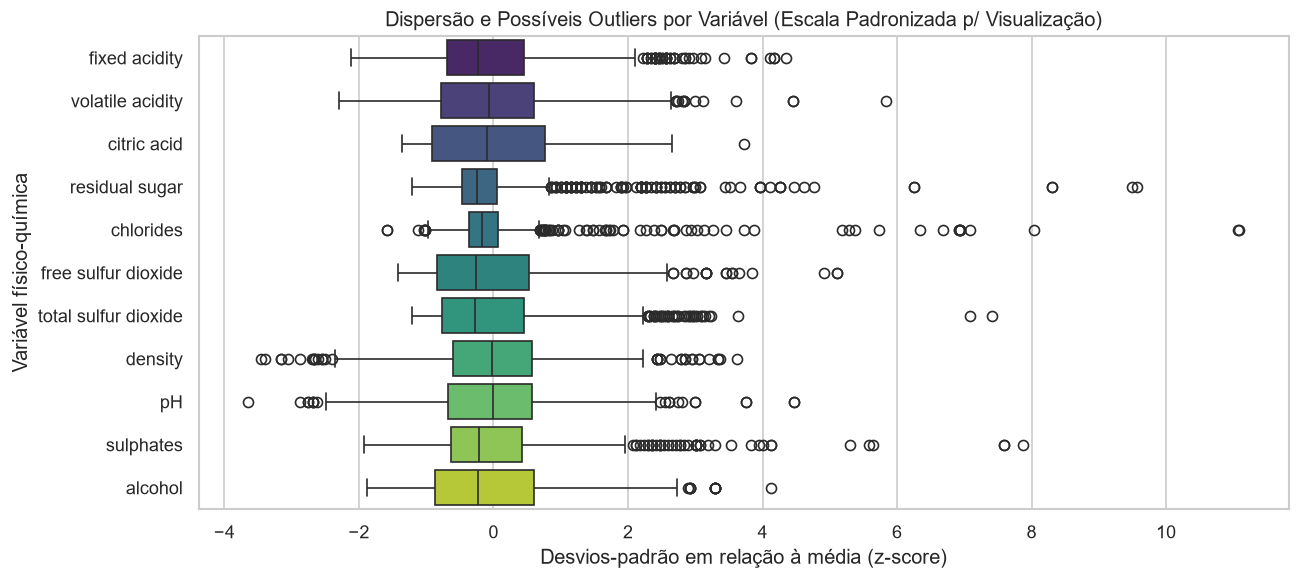

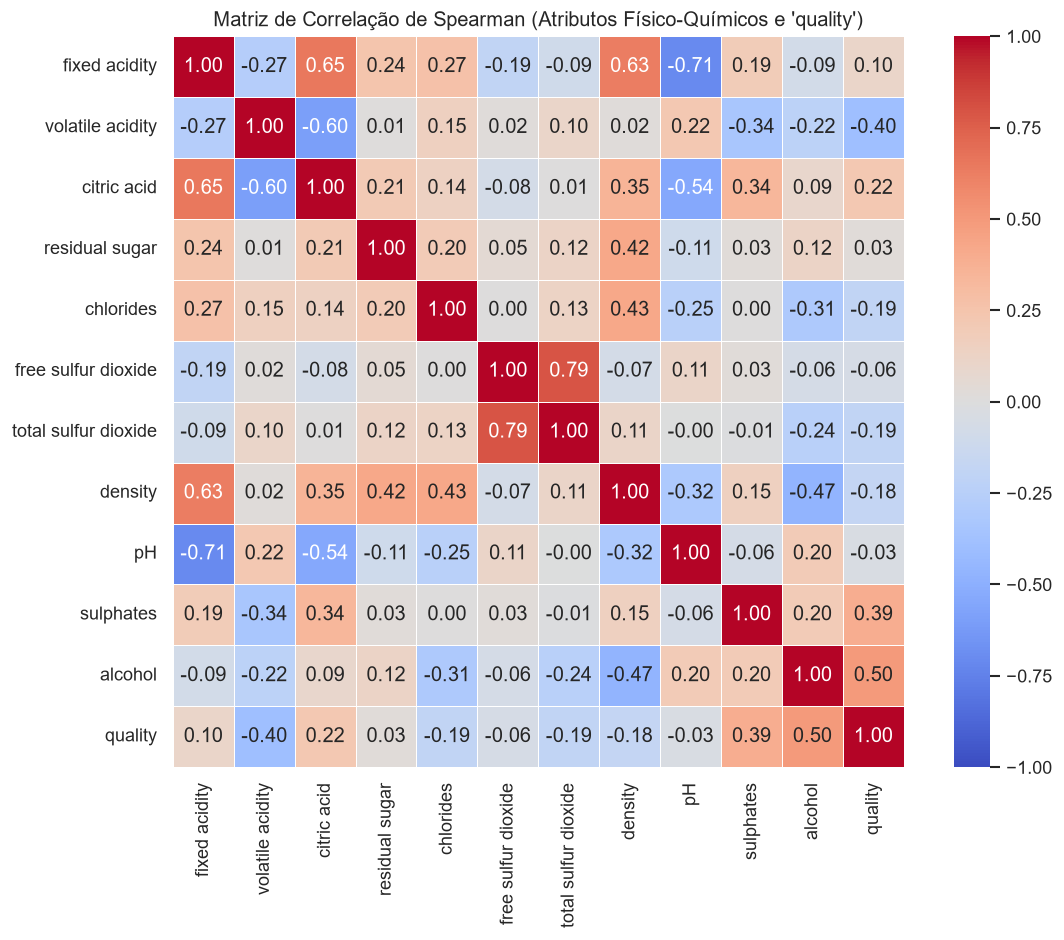

In [4]:
import matplotlib.pyplot as plt
import seaborn as sns

# Configuração visual consistente
sns.set_theme(style="whitegrid")
plt.rcParams["figure.dpi"] = 120

# 1. Boxplots das variáveis físico-químicas (normalizados por z-score apenas para visualização comparativa)
X_eda = df_eda.drop(columns=["quality", "target"])
X_scaled_vis = (X_eda - X_eda.mean()) / X_eda.std()

fig, ax = plt.subplots(figsize=(11, 5))
sns.boxplot(data=X_scaled_vis, orient="h", palette="viridis", ax=ax)
ax.set_title("Dispersão e Possíveis Outliers por Variável (Escala Padronizada p/ Visualização)", fontsize=12)
ax.set_xlabel("Desvios-padrão em relação à média (z-score)")
ax.set_ylabel("Variável físico-química")
plt.tight_layout()
plt.show()

# 2. Matriz de correlação de Spearman (avalia associações monotônicas e é menos sensível a valores extremos que Pearson)
corr_spearman = df_eda.drop(columns=["target"]).corr(method="spearman")

fig, ax = plt.subplots(figsize=(10, 8))
sns.heatmap(
    corr_spearman,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0,
    vmin=-1,
    vmax=1,
    square=True,
    linewidths=0.5,
    ax=ax,
)
ax.set_title("Matriz de Correlação de Spearman (Atributos Físico-Químicos e 'quality')", fontsize=12)
plt.tight_layout()
plt.show()

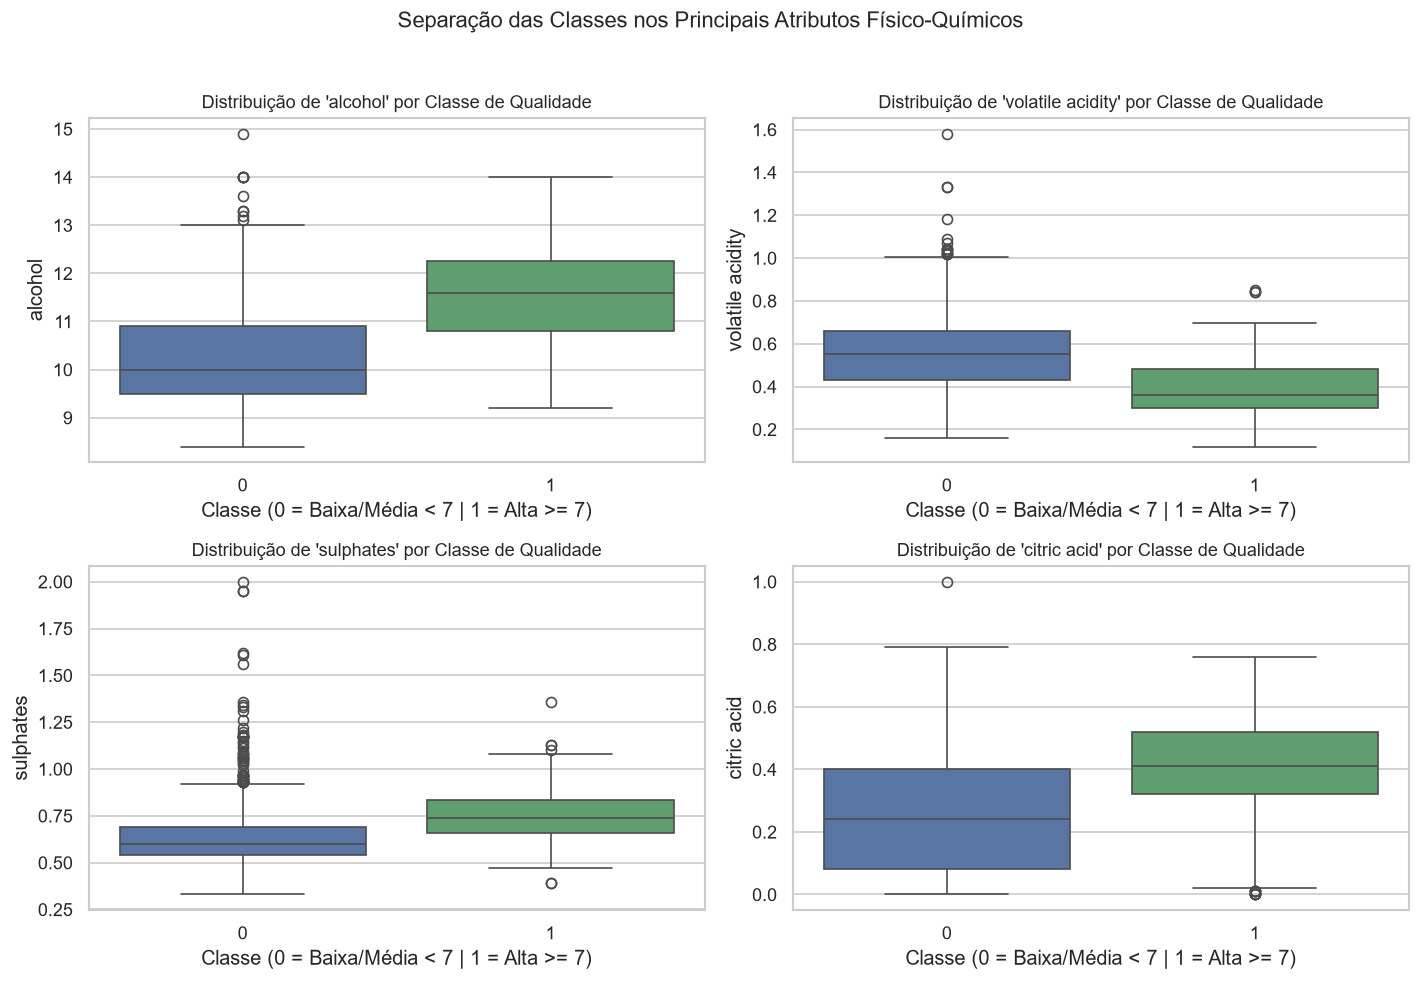

In [5]:
# Comparação de 4 atributos selecionados pela associação com a nota original 'quality' (Spearman)

top_features = ["alcohol", "volatile acidity", "sulphates", "citric acid"]

fig, axes = plt.subplots(2, 2, figsize=(12, 8))
axes = axes.flatten()

for ax, col in zip(axes, top_features):
    sns.boxplot(
        data=df_eda,
        x="target",
        y=col,
        hue="target",
        palette={0: "#4C72B0", 1: "#55A868"},
        legend=False,
        ax=ax,
    )
    ax.set_title(f"Distribuição de '{col}' por Classe de Qualidade", fontsize=11)
    ax.set_xlabel("Classe (0 = Baixa/Média < 7 | 1 = Alta >= 7)")
    ax.set_ylabel(col)

plt.suptitle("Separação das Classes nos Principais Atributos Físico-Químicos", fontsize=13, y=1.02)
plt.tight_layout()
plt.show()

### 2.2 Conclusões da Análise Exploratória de Dados (EDA)

A investigação exploratória da base `WineQT.csv` revelou padrões estruturais e físico-químicos essenciais para orientar o pré-processamento e a modelagem:

1. **Integridade e Estrutura dos Dados:**
   - A base original possui **1.143 registros e 13 colunas**, sem valores ausentes (`NaN`).
   - A coluna `Id` foi descartada da análise por ser apenas um identificador sequencial sem significado físico-químico.

2. **Registros Duplicados e Risco de *Data Leakage*:**
   - Foram identificados **125 registros excedentes** pertencentes a perfis físico-químicos repetidos, considerando também a nota de qualidade (restam **1.018 registros** após a deduplicação).

3. **Desbalanceamento de Classes (*Class Imbalance*):**
   - A variável-alvo binária (`target`: `1` se `quality >= 7`; `0` se `quality < 7`) é fortemente desbalanceada: **86,09%** de vinhos de Baixa/Média Qualidade contra **13,91%** de Alta Qualidade (proporção estrutural mantida mesmo após deduplicação: **86,54% vs. 13,46%**).
   
4. **Assimetrias e Possíveis *Outliers*:**
   - Variáveis como `residual sugar`, `chlorides`, `free sulfur dioxide` e `total sulfur dioxide` apresentam caudas longas à direita e valores máximos bem distantes da mediana e do terceiro quartil (Q3).
   - Essa característica merece atenção no pré-processamento. Nos experimentos deste projeto, `StandardScaler` foi aplicado dentro dos pipelines dos modelos sensíveis à escala. Uma comparação específica com `RobustScaler` não foi realizada e fica como possibilidade para estudos futuros.

5. **Correlações com a Qualidade (Spearman) e Justificativas Físico-Químicas:**
   - As variáveis com maior associação com `quality` são: **`alcohol` (+0,50)**, **`volatile acidity` (-0,40)**, **`sulphates` (+0,39)** e **`citric acid` (+0,22)**.
   - Entre os atributos preditores, destacam-se correlações fortes com fundamento químico claro — que também sinalizam potencial **multicolinearidade (*multicollinearity*)**:
     - `free sulfur dioxide` vs. `total sulfur dioxide` (**+0,79**): o SO₂ total é composto diretamente pela soma da fração livre com a fração combinada.
     - `fixed acidity` vs. `pH` (**-0,71**): quanto maior a concentração de ácidos fixos na solução, menor o pH (maior acidez).
     - `fixed acidity` vs. `citric acid` (**+0,65**): o ácido cítrico é um ácido não volátil que integra a acidez fixa.
     - `fixed acidity` vs. `density` (**+0,63**): maior concentração de ácidos e solutos dissolvidos eleva a densidade do líquido.
     - `density` vs. `alcohol` (**-0,47**): como o álcool é menos denso que a água, vinhos com maior teor alcoólico tendem a ter menor densidade.

6. **Perfil da Classe Positiva e Sobreposição (*Overlap*):**
   - Em termos de mediana, vinhos de **Alta Qualidade (`target = 1`)** tendem a apresentar **maior teor alcoólico**, **maiores níveis de sulfatos e ácido cítrico** e **menor acidez volátil**.
   - Entretanto, os *boxplots* evidenciam **sobreposição considerável (*overlap*)** entre as classes `0` e `1`. Nenhuma característica físico-química é determinística isoladamente, confirmando que a classificação é um problema **multivariado e probabilístico** que justifica o uso de algoritmos de Machine Learning.


## 3. Pré-processamento e *Feature Engineering*

### 3.1 Pré-processamento

In [6]:
from sklearn.model_selection import train_test_split
from statsmodels.stats.outliers_influence import variance_inflation_factor

# Constante global para reprodutibilidade
RANDOM_STATE = 2024

# 1. Remoção de duplicatas exatas para evitar vazamento entre treino e teste
df_model = df_eda.drop_duplicates().reset_index(drop=True)
print(f"Linhas antes: {len(df_eda)} | Depois: {len(df_model)}")

# 2. Separação entre atributos (X) e variável-alvo binária (y)
X = df_model.drop(columns=["quality", "target"])
y = df_model["target"]

# 3. Divisão estratificada em Treino (80%) e Teste (20%)
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    stratify=y,
    random_state=RANDOM_STATE,
)

print(f"Treino: {X_train.shape} | Proporção classe 1: {(y_train.sum()/len(y_train))*100:.2f}%")
print(f"Teste:  {X_test.shape} | Proporção classe 1: {(y_test.sum()/len(y_test))*100:.2f}%" )

Linhas antes: 1143 | Depois: 1018
Treino: (814, 11) | Proporção classe 1: 13.51%
Teste:  (204, 11) | Proporção classe 1: 13.24%


In [7]:
# Adiciona constante para cálculo estatisticamente correto do VIF
X_train_const = X_train.copy()
X_train_const["const"] = 1.0

vif_df = pd.DataFrame({
    "feature": X_train.columns,
    "VIF": [
        variance_inflation_factor(X_train_const.values, i)
        for i in range(X_train.shape[1])
    ],
}).sort_values(by="VIF", ascending=False).reset_index(drop=True)

display(vif_df.round(2))

,feature,VIF
0,fixed acidity,8.10
1,density,6.74
2,pH,3.55
3,alcohol,3.22
4,citric acid,3.15
5,total sulfur dioxide,2.13
6,free sulfur dioxide,1.92
7,residual sugar,1.77
8,volatile acidity,1.75
9,chlorides,1.67


### 3.2 Feature Engineering

In [8]:
from src.features import add_domain_features, RAW_FEATURES, MODEL_FEATURES

# Confere se a base de treino possui as mesmas variáveis originais esperadas.
if list(X_train.columns) != RAW_FEATURES:
    raise ValueError("A ordem ou os nomes das features originais diferem de src/features.py.")

# A mesma função será usada no script de predição de novos vinhos.
X_train_fe = add_domain_features(X_train)
X_test_fe = add_domain_features(X_test)

print(f"Features originais: {X_train.shape[1]} | Com Feature Engineering: {X_train_fe.shape[1]}")
display(X_train_fe[["free_sulfur_ratio", "volatile_to_fixed_acidity"]].describe().T.round(4))


Features originais: 11 | Com Feature Engineering: 13


,count,mean,std,min,25%,50%,75%,max
free_sulfur_ratio,814.0,0.378,0.1492,0.0357,0.2582,0.3750,0.4750,0.8571
volatile_to_fixed_acidity,814.0,0.068,0.0291,0.0135,0.0446,0.0661,0.0865,0.2080


### 3.3 Decisões e Conclusões do Pré-processamento e *Feature Engineering*

Nesta etapa, preparamos os dados com foco rigoroso em **reprodutibilidade** (`RANDOM_STATE = 2024`) e **prevenção de *Data Leakage***:

1. **Deduplicação antes do *Split*:**
   - A auditoria identificou **125 registros excedentes** em perfis físico-químicos repetidos. Após manter a primeira ocorrência de cada perfil, a base passa de **1.143 para 1.018 registros**.
   - Os 114 perfis repetidos não apresentam divergência na nota `quality`. Ainda assim, não há metadados suficientes para afirmar que representam a mesma amostra física.
   - **Justificativa metodológica:** a deduplicação é adotada como uma premissa conservadora para reduzir o risco de vetores de atributos idênticos aparecerem simultaneamente no treino e no teste. Essa decisão e sua incerteza devem ser consideradas uma limitação do estudo; uma análise de sensibilidade com validação agrupada pode ser realizada como próximo passo.

2. **Divisão Estratificada (*Stratified Train-Test Split — 80/20*):**
   - **Treino (`X_train`):** 814 amostras (**13,51%** de vinhos de Alta Qualidade).
   - **Teste (`X_test`):** 204 amostras (**13,24%** de vinhos de Alta Qualidade).
   - O conjunto de teste permanece isolado até a avaliação final dos modelos.

3. **Diagnóstico de Multicolinearidade (*VIF — Variance Inflation Factor*):**
   - Calculado **exclusivamente sobre `X_train`** (com inclusão de constante estatística).
   - Apenas duas variáveis ficaram acima do patamar de atenção ($\text{VIF} > 5$), mas nenhuma atingiu o nível crítico ($\text{VIF} \ge 10$): **`fixed acidity` (8,10)** e **`density` (6,74)**. Todas as demais ficaram abaixo de 4.
   - **Decisão:** manter todas as 11 variáveis originais nesta fase. Algoritmos baseados em árvores são praticamente imunes à multicolinearidade, e modelos lineares com regularização L2 (*Ridge*) conseguem controlar essa redundância. O impacto da eventual remoção dessas variáveis poderá ser testado em experimento controlado.

4. **Escalonamento (*Feature Scaling*) dentro de *Pipelines*:**
   - Nos experimentos executados, `StandardScaler` é utilizado dentro de `Pipeline` para Regressão Logística, KNN e SVM, algoritmos sensíveis à escala das variáveis. Os modelos baseados em árvores (Random Forest e Gradient Boosting) não recebem escalonamento.
   - `RobustScaler` foi considerado devido às assimetrias e aos possíveis *outliers*, mas **não foi incluído na comparação executada**. Portanto, não devemos afirmar que seus resultados foram testados.
   - **Justificativa:** manter o `StandardScaler` dentro dos *Pipelines* garante que médias e desvios-padrão sejam calculados somente nos dados de treino de cada divisão, evitando *Data Leakage*. Uma comparação com `RobustScaler` pode ser registrada como experimento futuro, se houver justificativa.

5. ***Feature Engineering* Orientado ao Domínio:**
   - Foram criadas duas variáveis derivadas calculadas linha a linha (sem uso de estatísticas globais, portanto sem *Data Leakage*):
     - **`free_sulfur_ratio`** (`free sulfur dioxide / total sulfur dioxide`): proporção de dióxido de enxofre livre em relação ao dióxido de enxofre total medido; não representa diretamente a fração molecular ativa.
     - **`volatile_to_fixed_acidity`** (`volatile acidity / fixed acidity`): peso da acidez volátil (indesejável em excesso) em relação à acidez estrutural.
   - O conjunto passou de **11 para 13 atributos** (`X_train_fe` e `X_test_fe`), que serão comparados contra as variáveis originais para validar se realmente agregam poder preditivo.

## 4. Desenvolvimento dos Modelos de Machine Learning

### 4.1 Validação Cruzada e Baselines


In [9]:
from sklearn.model_selection import StratifiedKFold, cross_validate
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression

# 1. Estratégia de validação cruzada estratificada (5 folds)
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

# 2. Métricas que acompanharemos em todos os modelos
scoring = {
    "accuracy": "accuracy",
    "precision": "precision",
    "recall": "recall",
    "f1": "f1",
    "roc_auc": "roc_auc",
    "pr_auc": "average_precision",
}

# 3. Definição dos modelos baseline (encapsulados em Pipeline para evitar Data Leakage)
baselines = {
    "Dummy (Most Frequent)": DummyClassifier(strategy="most_frequent"),
    "Logistic Regression (Default)": Pipeline([
        ("scaler", StandardScaler()),
        ("model", LogisticRegression(random_state=RANDOM_STATE)),
    ]),
    "Logistic Regression (Balanced)": Pipeline([
        ("scaler", StandardScaler()),
        ("model", LogisticRegression(class_weight="balanced", random_state=RANDOM_STATE)),
    ]),
}

# 4. Execução da validação cruzada apenas em X_train e y_train
results_baseline = []
for name, model in baselines.items():
    scores = cross_validate(model, X_train, y_train, cv=cv, scoring=scoring, n_jobs=-1)
    results_baseline.append({
        "Modelo": name,
        "Accuracy": scores["test_accuracy"].mean(),
        "Precision": scores["test_precision"].mean(),
        "Recall": scores["test_recall"].mean(),
        "F1-Score": scores["test_f1"].mean(),
        "ROC-AUC": scores["test_roc_auc"].mean(),
        "PR-AUC": scores["test_pr_auc"].mean(),
    })

df_baselines = pd.DataFrame(results_baseline).round(4)
display(df_baselines)

,Modelo,Accuracy,Precision,Recall,F1-Score,ROC-AUC,PR-AUC
0,Dummy (Most Frequent),0.8649,0.0000,0.0000,0.0000,0.5000,0.1351
1,Logistic Regression (Default),0.8845,0.6227,0.3818,0.4699,0.8854,0.5472
2,Logistic Regression (Balanced),0.7949,0.3795,0.8182,0.5180,0.8838,0.5429


### 4.2 Explorando Múltiplas Famílias de Algoritmos

In [10]:
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.svm import SVC
from sklearn.calibration import CalibratedClassifierCV

# O scaler fica dentro do estimador calibrado. Assim, em cada divisão interna
# da calibração, o StandardScaler é ajustado somente nos dados daquele fold.
calibration_cv = StratifiedKFold(
    n_splits=3,
    shuffle=True,
    random_state=RANDOM_STATE,
)

svm_calibration_pipeline = Pipeline([
    ("scaler", StandardScaler()),
    ("svc", SVC(kernel="rbf", random_state=RANDOM_STATE)),
])

candidate_models = {
    "Logistic Regression (Default)": Pipeline([
        ("scaler", StandardScaler()),
        ("model", LogisticRegression(random_state=RANDOM_STATE)),
    ]),
    "KNN (k=7)": Pipeline([
        ("scaler", StandardScaler()),
        ("model", KNeighborsClassifier(n_neighbors=7)),
    ]),
    "Decision Tree (max_depth=5)": DecisionTreeClassifier(
        max_depth=5, random_state=RANDOM_STATE
    ),
    "Random Forest": RandomForestClassifier(
        n_estimators=200, random_state=RANDOM_STATE, n_jobs=1
    ),
    "SVM (RBF)": CalibratedClassifierCV(
        estimator=svm_calibration_pipeline,
        method="sigmoid",
        cv=calibration_cv,
        ensemble=False,
        n_jobs=1,
    ),
    "Gradient Boosting": GradientBoostingClassifier(random_state=RANDOM_STATE),
}

all_results = []
for name, model in candidate_models.items():
    scores = cross_validate(model, X_train, y_train, cv=cv, scoring=scoring, n_jobs=-1)
    all_results.append({
        "Modelo": name,
        "Accuracy": scores["test_accuracy"].mean(),
        "Precision": scores["test_precision"].mean(),
        "Recall": scores["test_recall"].mean(),
        "F1-Score": scores["test_f1"].mean(),
        "ROC-AUC": scores["test_roc_auc"].mean(),
        "PR-AUC": scores["test_pr_auc"].mean(),
    })

df_models_cv = (
    pd.DataFrame(all_results)
    .sort_values(by="PR-AUC", ascending=False)
    .reset_index(drop=True)
    .round(4)
)
display(df_models_cv)


,Modelo,Accuracy,Precision,Recall,F1-Score,ROC-AUC,PR-AUC
0,Random Forest,0.8919,0.6857,0.4091,0.5011,0.8867,0.5971
1,SVM (RBF),0.8857,0.6209,0.3727,0.4576,0.8668,0.5812
2,Gradient Boosting,0.8857,0.6185,0.4364,0.5025,0.8683,0.5474
3,Logistic Regression (Default),0.8845,0.6227,0.3818,0.4699,0.8854,0.5472
4,KNN (k=7),0.8759,0.5585,0.3909,0.4562,0.8293,0.4356
5,Decision Tree (max_depth=5),0.8698,0.5234,0.3818,0.4321,0.7732,0.3706


### 4.3 Otimização de Hiperparâmetros e Teste das Features

In [11]:
from sklearn.model_selection import GridSearchCV
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.calibration import CalibratedClassifierCV
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier

# A calibração de probabilidades do SVM encapsula também o pré-processamento.
calibration_cv = StratifiedKFold(
    n_splits=3,
    shuffle=True,
    random_state=RANDOM_STATE,
)
svm_calibration_pipeline = Pipeline([
    ("scaler", StandardScaler()),
    ("svc", SVC(kernel="rbf", random_state=RANDOM_STATE)),
])

# Random Forest usa n_jobs=1 para evitar paralelismo aninhado; o GridSearchCV
# será responsável por distribuir os ajustes entre os núcleos disponíveis.
search_configs = {
    "Logistic Regression": (
        Pipeline([
            ("scaler", StandardScaler()),
            ("model", LogisticRegression(random_state=RANDOM_STATE, max_iter=1000)),
        ]),
        {"model__C": [0.01, 0.1, 1.0, 10.0]},
    ),
    "KNN": (
        Pipeline([
            ("scaler", StandardScaler()),
            ("model", KNeighborsClassifier()),
        ]),
        {
            "model__n_neighbors": [5, 9, 13, 19, 25],
            "model__weights": ["uniform", "distance"],
        },
    ),
    "SVM RBF": (
        CalibratedClassifierCV(
            estimator=svm_calibration_pipeline,
            method="sigmoid",
            cv=calibration_cv,
            ensemble=False,
            n_jobs=1,
        ),
        {
            "estimator__svc__C": [0.1, 1.0, 10.0],
            "estimator__svc__gamma": ["scale", 0.01, 0.1],
        },
    ),
    "Random Forest": (
        RandomForestClassifier(random_state=RANDOM_STATE, n_jobs=1),
        {
            "n_estimators": [150, 300],
            "max_depth": [4, 6, 8, None],
            "min_samples_leaf": [1, 3, 5],
        },
    ),
    "Gradient Boosting": (
        GradientBoostingClassifier(random_state=RANDOM_STATE),
        {
            "n_estimators": [100, 200],
            "learning_rate": [0.03, 0.05, 0.1],
            "max_depth": [2, 3, 4],
        },
    ),
}

datasets_fe = {
    "11 Features": X_train,
    "13 Features (FE)": X_train_fe,
}

# Busca exploratória de hiperparâmetros. best_score_ ajuda a escolher parâmetros,
# mas não é uma estimativa independente do desempenho. Essa estimativa virá
# da Nested Cross-Validation na Etapa 5.
tuned_models = {}
tuning_rows = []

for ds_label, X_curr in datasets_fe.items():
    for name, (estimator, param_grid) in search_configs.items():
        grid = GridSearchCV(
            estimator=estimator,
            param_grid=param_grid,
            cv=cv,
            scoring="average_precision",
            n_jobs=-1,
            refit=True,
            error_score="raise",
        )
        grid.fit(X_curr, y_train)
        tuned_models[f"{name} | {ds_label}"] = (grid.best_estimator_, ds_label)
        tuning_rows.append({
            "Modelo": name,
            "Conjunto": ds_label,
            "Best CV PR-AUC (busca)": round(grid.best_score_, 4),
            "Melhores Hiperparâmetros": str(grid.best_params_),
        })

df_tuning_comp = (
    pd.DataFrame(tuning_rows)
    .sort_values(by="Best CV PR-AUC (busca)", ascending=False)
    .reset_index(drop=True)
)

df_11 = df_tuning_comp[df_tuning_comp["Conjunto"] == "11 Features"].set_index("Modelo")
df_13 = df_tuning_comp[df_tuning_comp["Conjunto"] == "13 Features (FE)"].set_index("Modelo")
df_resumo_etapa4 = pd.DataFrame({
    "PR-AUC busca (11 Feat)": df_11["Best CV PR-AUC (busca)"],
    "Params (11 Feat)": df_11["Melhores Hiperparâmetros"],
    "PR-AUC busca (13 Feat)": df_13["Best CV PR-AUC (busca)"],
    "Params (13 Feat)": df_13["Melhores Hiperparâmetros"],
})
df_resumo_etapa4["Ganho FE (busca)"] = (
    df_resumo_etapa4["PR-AUC busca (13 Feat)"] - df_resumo_etapa4["PR-AUC busca (11 Feat)"]
).round(4)
df_resumo_etapa4 = df_resumo_etapa4.sort_values(
    by="PR-AUC busca (13 Feat)", ascending=False
)
with pd.option_context("display.max_colwidth", None, "display.width", 1000):
    display(df_resumo_etapa4)


,PR-AUC busca (11 Feat),Params (11 Feat),PR-AUC busca (13 Feat),Params (13 Feat),Ganho FE (busca)
Modelo,,,,,
Random Forest,0.5939,"{'max_depth': 8, 'min_samples_leaf': 3, 'n_estimators': 150}",0.6091,"{'max_depth': 6, 'min_samples_leaf': 1, 'n_estimators': 300}",0.0152
SVM RBF,0.5892,"{'estimator__svc__C': 1.0, 'estimator__svc__gamma': 0.1}",0.6033,"{'estimator__svc__C': 1.0, 'estimator__svc__gamma': 0.1}",0.0141
KNN,0.5676,"{'model__n_neighbors': 25, 'model__weights': 'distance'}",0.5902,"{'model__n_neighbors': 25, 'model__weights': 'distance'}",0.0226
Gradient Boosting,0.5611,"{'learning_rate': 0.03, 'max_depth': 4, 'n_estimators': 200}",0.5796,"{'learning_rate': 0.05, 'max_depth': 3, 'n_estimators': 100}",0.0185
Logistic Regression,0.5654,{'model__C': 0.01},0.5659,{'model__C': 0.01},0.0005


### 4.4 Síntese e Decisões do Desenvolvimento dos Modelos

Nesta etapa, realizamos uma busca exploratória de hiperparâmetros e comparamos cinco famílias de algoritmos nas 11 variáveis originais e nas 13 variáveis com *Feature Engineering*.

1. **Validação cruzada e *baselines*:** a validação estratificada preserva a proporção da classe minoritária. O `DummyClassifier` evidencia por que a acurácia isolada não é adequada para este problema desbalanceado.
2. **Famílias de algoritmos:** comparamos Regressão Logística, KNN, SVM RBF, Random Forest e Gradient Boosting. A Árvore de Decisão também foi utilizada como referência exploratória.
3. **Busca de hiperparâmetros:** o `GridSearchCV` seleciona configurações usando `average_precision` (PR-AUC). Os valores `best_score_` apresentados nesta etapa são resultados da própria busca e, portanto, não devem ser interpretados como uma estimativa independente de generalização.
4. **Comparação de features:** a tabela compara a busca nas 11 variáveis originais com a busca nas 13 variáveis após *Feature Engineering*. A contribuição dessas variáveis será reavaliada com um procedimento de validação aninhada na Etapa 5.

A avaliação aninhada (*Nested Cross-Validation*) separará a seleção de hiperparâmetros da estimativa de desempenho: a validação interna otimiza o modelo e a validação externa estima seu desempenho em dados não utilizados nessa otimização.


## 5. Avaliação e Comparação dos Modelos

### 5.1 Diagnóstico de Overfitting / Underfitting

In [12]:
from sklearn.base import clone
from sklearn.metrics import average_precision_score, roc_auc_score
from sklearn.model_selection import GridSearchCV, StratifiedKFold

# Validação externa: estima o desempenho da estratégia completa de modelagem.
outer_cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=RANDOM_STATE + 1,
)

# Validação interna: escolhe hiperparâmetros dentro de cada fold externo.
inner_cv = StratifiedKFold(
    n_splits=4,
    shuffle=True,
    random_state=RANDOM_STATE,
)

nested_summary_rows = []
nested_fold_rows = []
nested_oof_probabilities = {}
nested_best_params = {}

for dataset_name, X_current in datasets_fe.items():
    for model_name, (estimator, param_grid) in search_configs.items():
        config_key = f"{model_name} | {dataset_name}"
        print(f"Executando Nested CV: {config_key}")

        # Cada linha recebe uma probabilidade prevista por um modelo que não
        # utilizou aquela observação nem para ajuste nem para seleção de parâmetros.
        oof_probabilities = np.full(shape=len(y_train), fill_value=np.nan, dtype=float)
        fold_pr_auc = []
        fold_roc_auc = []
        params_by_fold = []

        for fold, (train_idx, valid_idx) in enumerate(
            outer_cv.split(X_current, y_train), start=1
        ):
            X_outer_train = X_current.iloc[train_idx]
            X_outer_valid = X_current.iloc[valid_idx]
            y_outer_train = y_train.iloc[train_idx]
            y_outer_valid = y_train.iloc[valid_idx]

            # A busca de hiperparâmetros acontece somente no treino do fold externo.
            inner_search = GridSearchCV(
                estimator=clone(estimator),
                param_grid=param_grid,
                scoring="average_precision",
                cv=inner_cv,
                n_jobs=-1,
                refit=True,
                error_score="raise",
            )
            inner_search.fit(X_outer_train, y_outer_train)

            fold_proba = inner_search.predict_proba(X_outer_valid)[:, 1]
            oof_probabilities[valid_idx] = fold_proba

            pr_auc = average_precision_score(y_outer_valid, fold_proba)
            roc_auc = roc_auc_score(y_outer_valid, fold_proba)
            fold_pr_auc.append(pr_auc)
            fold_roc_auc.append(roc_auc)
            params_by_fold.append(inner_search.best_params_)

            nested_fold_rows.append({
                "Configuração": config_key,
                "Fold externo": fold,
                "PR-AUC": pr_auc,
                "ROC-AUC": roc_auc,
                "Melhores parâmetros": str(inner_search.best_params_),
            })

        if np.isnan(oof_probabilities).any():
            raise RuntimeError(f"Há previsões OOF ausentes em {config_key}.")

        nested_oof_probabilities[config_key] = oof_probabilities
        nested_best_params[config_key] = params_by_fold

        nested_summary_rows.append({
            "Configuração": config_key,
            "Modelo": model_name,
            "Conjunto": dataset_name,
            "Nested PR-AUC (média)": np.mean(fold_pr_auc),
            "Nested PR-AUC (DP)": np.std(fold_pr_auc, ddof=1),
            "Nested ROC-AUC (média)": np.mean(fold_roc_auc),
            "PR-AUC OOF (agregada)": average_precision_score(y_train, oof_probabilities),
        })

# Principal comparação: média da PR-AUC nos folds externos; o desvio-padrão
# mostra quanto o desempenho variou entre as divisões.
df_nested_cv = (
    pd.DataFrame(nested_summary_rows)
    .sort_values("Nested PR-AUC (média)", ascending=False)
    .reset_index(drop=True)
)
df_nested_cv_display = df_nested_cv.copy()
metric_cols = [
    "Nested PR-AUC (média)",
    "Nested PR-AUC (DP)",
    "Nested ROC-AUC (média)",
    "PR-AUC OOF (agregada)",
]
df_nested_cv_display[metric_cols] = df_nested_cv_display[metric_cols].round(4)
display(df_nested_cv_display)

# Mantém também o detalhamento por fold para auditoria e discussão da estabilidade.
df_nested_folds = pd.DataFrame(nested_fold_rows)
display(df_nested_folds.round(4))


Executando Nested CV: Logistic Regression | 11 Features
Executando Nested CV: KNN | 11 Features
Executando Nested CV: SVM RBF | 11 Features
Executando Nested CV: Random Forest | 11 Features
Executando Nested CV: Gradient Boosting | 11 Features
Executando Nested CV: Logistic Regression | 13 Features (FE)
Executando Nested CV: KNN | 13 Features (FE)
Executando Nested CV: SVM RBF | 13 Features (FE)
Executando Nested CV: Random Forest | 13 Features (FE)
Executando Nested CV: Gradient Boosting | 13 Features (FE)


,Configuração,Modelo,Conjunto,Nested PR-AUC (média),Nested PR-AUC (DP),Nested ROC-AUC (média),PR-AUC OOF (agregada)
0,Random Forest | 13 Features (FE),Random Forest,13 Features (FE),0.5804,0.0426,0.8854,0.5518
1,Random Forest | 11 Features,Random Forest,11 Features,0.5710,0.0512,0.8820,0.5555
2,SVM RBF | 13 Features (FE),SVM RBF,13 Features (FE),0.5625,0.0591,0.8545,0.5314
3,KNN | 13 Features (FE),KNN,13 Features (FE),0.5620,0.0601,0.8656,0.5460
4,SVM RBF | 11 Features,SVM RBF,11 Features,0.5456,0.0579,0.8630,0.5192
5,KNN | 11 Features,KNN,11 Features,0.5441,0.0641,0.8700,0.5326
6,Gradient Boosting | 13 Features (FE),Gradient Boosting,13 Features (FE),0.5399,0.0569,0.8797,0.4777
7,Logistic Regression | 11 Features,Logistic Regression,11 Features,0.5368,0.0426,0.8864,0.4928
8,Gradient Boosting | 11 Features,Gradient Boosting,11 Features,0.5312,0.0175,0.8811,0.4995
9,Logistic Regression | 13 Features (FE),Logistic Regression,13 Features (FE),0.5243,0.0498,0.8834,0.4975


,Configuração,Fold externo,PR-AUC,ROC-AUC,Melhores parâmetros
0,Logistic Regression | 11 Features,1,0.6041,0.9307,{'model__C': 0.01}
1,Logistic Regression | 11 Features,2,0.5097,0.8772,{'model__C': 0.1}
2,Logistic Regression | 11 Features,3,0.5075,0.8575,{'model__C': 0.1}
3,Logistic Regression | 11 Features,4,0.5080,0.8846,{'model__C': 0.01}
4,Logistic Regression | 11 Features,5,0.5547,0.8818,{'model__C': 0.01}
5,KNN | 11 Features,1,0.6083,0.9201,"{'model__n_neighbors': 25, 'model__weights': '..."
6,KNN | 11 Features,2,0.4946,0.8486,"{'model__n_neighbors': 19, 'model__weights': '..."
7,KNN | 11 Features,3,0.4638,0.8187,"{'model__n_neighbors': 25, 'model__weights': '..."
8,KNN | 11 Features,4,0.5518,0.8868,"{'model__n_neighbors': 25, 'model__weights': '..."
9,KNN | 11 Features,5,0.6023,0.8760,"{'model__n_neighbors': 19, 'model__weights': '..."


### 5.2 Comparação de Cenários de *Threshold* com Previsões OOF da Nested CV

Em vez de escolher automaticamente um *threshold* por uma regra numérica arbitrária, vamos comparar três cenários previamente definidos. As probabilidades utilizadas nesta etapa são *out-of-fold* (OOF) da validação externa da Nested CV: cada observação do treino recebe uma previsão de um modelo cuja seleção de hiperparâmetros não utilizou aquela observação.

| Cenário | Threshold | Interpretação |
|---|---:|---|
| **Padrão** | 0,50 | Ponto de referência convencional para converter probabilidade em classe. |
| **Intermediário** | 0,60 | Exige evidência um pouco maior para classificar uma amostra como Alta Qualidade. |
| **Conservador** | 0,70 | Torna a classificação positiva mais restritiva, em geral elevando Precision e reduzindo Recall. |

Os três valores são **cenários de sensibilidade**, não limites comprovadamente ótimos. Sem dados sobre custos de Falsos Positivos e Falsos Negativos, capacidade de inspeção e consequências comerciais, não há base suficiente para declarar um único *threshold* como melhor. A comparação mostrará o efeito de cada cenário sobre Precision, Recall, F1-Score e quantidade de amostras sinalizadas.

Para não eliminar prematuramente modelos com resultados próximos, todas as cinco famílias de algoritmos serão comparadas. Em cada família, utilizaremos o conjunto de *features* (11 ou 13) com maior PR-AUC média na Nested CV.

**Nota sobre calibração:** os *thresholds* são aplicados às saídas `predict_proba`. Essas saídas são escores probabilísticos do modelo, mas nem todo algoritmo produz probabilidades perfeitamente calibradas. Antes de uma aplicação real, será importante avaliar a calibração (por exemplo, com curva de calibração e Brier Score).

In [13]:
from sklearn.metrics import precision_score, recall_score, f1_score, confusion_matrix

# Mantém uma configuração por família de algoritmo: aquela com maior PR-AUC
# média na Nested CV. Todas as cinco famílias serão comparadas nos mesmos cenários.
finalists_df = (
    df_nested_cv
    .sort_values("Nested PR-AUC (média)", ascending=False)
    .drop_duplicates(subset=["Modelo"])
    .reset_index(drop=True)
)
display(finalists_df.round(4))

# Cenários definidos antes da avaliação no conjunto de teste.
threshold_scenarios = {
    0.50: "Padrão",
    0.60: "Intermediário",
    0.70: "Conservador",
}
threshold_grid = np.round(np.arange(0.20, 0.851, 0.01), 2)

# Compara o impacto dos três cenários sobre as previsões OOF de cada finalista.
threshold_rows = []
for row in finalists_df.itertuples(index=False):
    config_key = row.Configuração
    oof_proba = nested_oof_probabilities[config_key]

    for threshold, scenario_name in threshold_scenarios.items():
        predictions = (oof_proba >= threshold).astype(int)
        tn, fp, fn, tp = confusion_matrix(y_train, predictions, labels=[0, 1]).ravel()
        threshold_rows.append({
            "Configuração": config_key,
            "Modelo": row.Modelo,
            "Conjunto": row.Conjunto,
            "Cenário": scenario_name,
            "Threshold": threshold,
            "Qtd. previstas como alta": int(predictions.sum()),
            "Precision": precision_score(y_train, predictions, zero_division=0),
            "Recall": recall_score(y_train, predictions, zero_division=0),
            "F1-Score": f1_score(y_train, predictions, zero_division=0),
            "VP": tp,
            "FP": fp,
            "FN": fn,
            "VN": tn,
        })

df_threshold_scenarios_oof = (
    pd.DataFrame(threshold_rows)
    .merge(
        df_nested_cv[["Configuração", "Nested PR-AUC (média)"]],
        on="Configuração",
        how="left",
    )
)
display(
    df_threshold_scenarios_oof
    .sort_values(["Nested PR-AUC (média)", "Threshold"], ascending=[False, True])
    .round(4)
)

# A escolha da configuração do modelo é independente do threshold:
# selecionamos a maior PR-AUC média entre as cinco configurações finalistas,
# sem consultar o teste. A diferença entre médias é descritiva, não prova
# superioridade estatística definitiva.
chosen_row = finalists_df.iloc[0]
chosen_config_key = chosen_row["Configuração"]
chosen_model_name = chosen_row["Modelo"]
chosen_dataset_name = chosen_row["Conjunto"]

print(f"Configuração candidata principal: {chosen_config_key}")
print(f"Nested PR-AUC média: {chosen_row['Nested PR-AUC (média)']:.4f}")
print(
    "Critério de escolha do modelo: maior média de PR-AUC nos folds externos da Nested CV. "
    "Os três thresholds permanecem como cenários para comparação; nenhum é declarado ótimo."
)

,Configuração,Modelo,Conjunto,Nested PR-AUC (média),Nested PR-AUC (DP),Nested ROC-AUC (média),PR-AUC OOF (agregada)
0,Random Forest | 13 Features (FE),Random Forest,13 Features (FE),0.5804,0.0426,0.8854,0.5518
1,SVM RBF | 13 Features (FE),SVM RBF,13 Features (FE),0.5625,0.0591,0.8545,0.5314
2,KNN | 13 Features (FE),KNN,13 Features (FE),0.5620,0.0601,0.8656,0.5460
3,Gradient Boosting | 13 Features (FE),Gradient Boosting,13 Features (FE),0.5399,0.0569,0.8797,0.4777
4,Logistic Regression | 11 Features,Logistic Regression,11 Features,0.5368,0.0426,0.8864,0.4928


,Configuração,Modelo,Conjunto,Cenário,Threshold,Qtd. previstas como alta,Precision,Recall,F1-Score,VP,FP,FN,VN,Nested PR-AUC (média)
0,Random Forest | 13 Features (FE),Random Forest,13 Features (FE),Padrão,0.5,42,0.6905,0.2636,0.3816,29,13,81,691,0.5804
1,Random Forest | 13 Features (FE),Random Forest,13 Features (FE),Intermediário,0.6,14,0.6429,0.0818,0.1452,9,5,101,699,0.5804
2,Random Forest | 13 Features (FE),Random Forest,13 Features (FE),Conservador,0.7,3,1.0000,0.0273,0.0531,3,0,107,704,0.5804
3,SVM RBF | 13 Features (FE),SVM RBF,13 Features (FE),Padrão,0.5,62,0.5806,0.3273,0.4186,36,26,74,678,0.5625
4,SVM RBF | 13 Features (FE),SVM RBF,13 Features (FE),Intermediário,0.6,45,0.6444,0.2636,0.3742,29,16,81,688,0.5625
5,SVM RBF | 13 Features (FE),SVM RBF,13 Features (FE),Conservador,0.7,31,0.6774,0.1909,0.2979,21,10,89,694,0.5625
6,KNN | 13 Features (FE),KNN,13 Features (FE),Padrão,0.5,58,0.6034,0.3182,0.4167,35,23,75,681,0.5620
7,KNN | 13 Features (FE),KNN,13 Features (FE),Intermediário,0.6,29,0.6552,0.1727,0.2734,19,10,91,694,0.5620
8,KNN | 13 Features (FE),KNN,13 Features (FE),Conservador,0.7,13,0.7692,0.0909,0.1626,10,3,100,701,0.5620
9,Gradient Boosting | 13 Features (FE),Gradient Boosting,13 Features (FE),Padrão,0.5,64,0.5312,0.3091,0.3908,34,30,76,674,0.5399


Configuração candidata principal: Random Forest | 13 Features (FE)
Nested PR-AUC média: 0.5804
Critério de escolha do modelo: maior média de PR-AUC nos folds externos da Nested CV. Os três thresholds permanecem como cenários para comparação; nenhum é declarado ótimo.


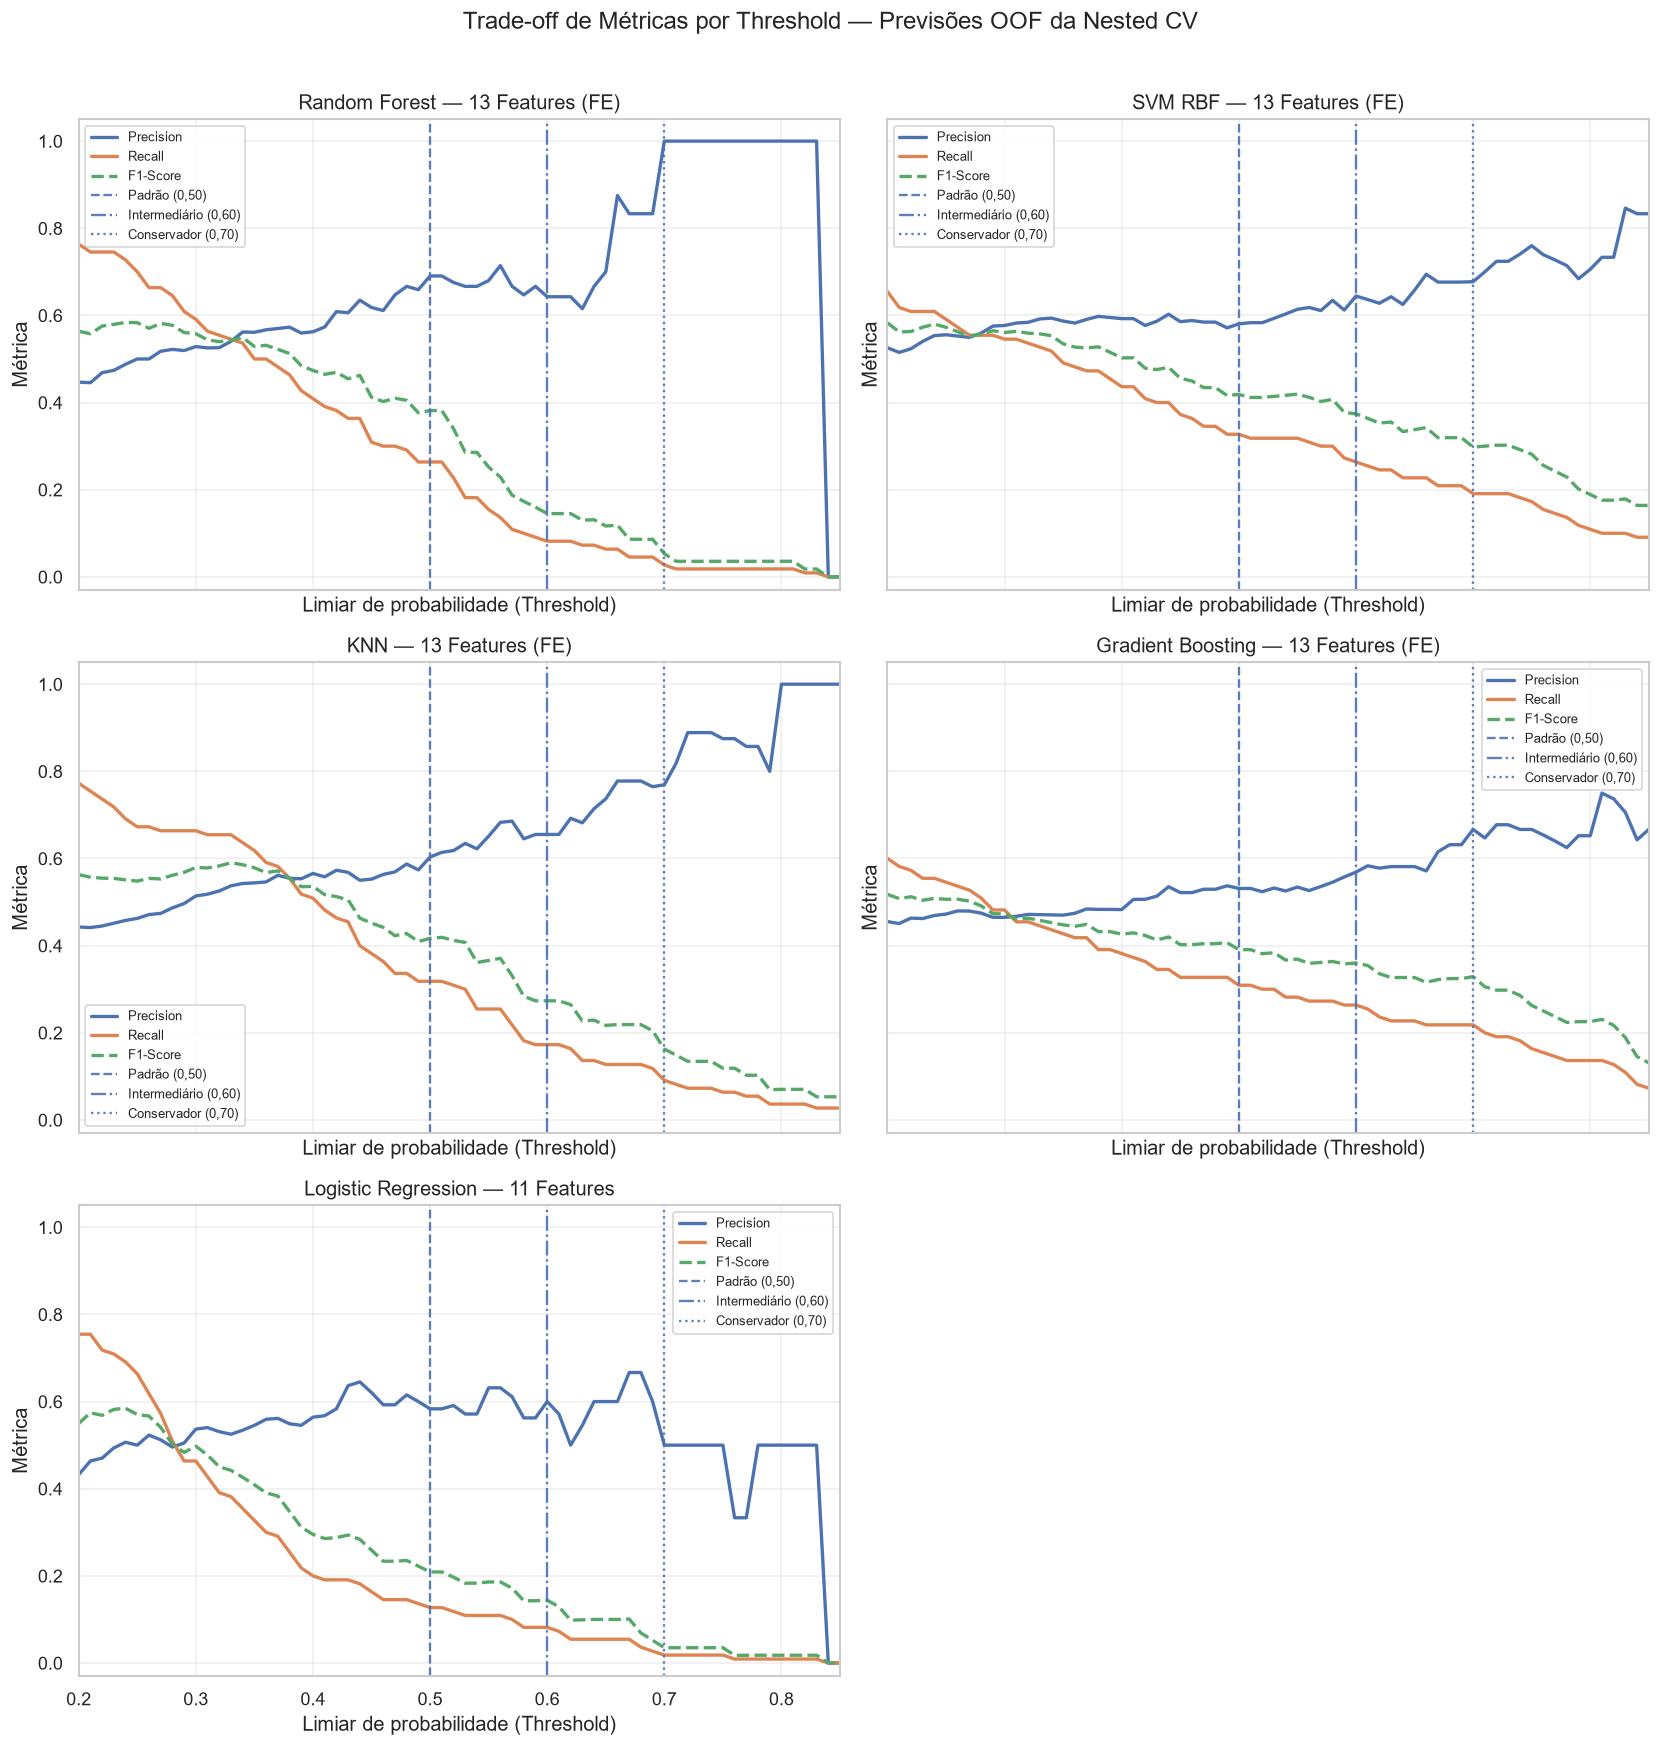

In [14]:
import matplotlib.pyplot as plt

ncols = 2
nrows = int(np.ceil(len(finalists_df) / ncols))
fig, axes = plt.subplots(
    nrows,
    ncols,
    figsize=(14, 4.8 * nrows),
    sharex=True,
    sharey=True,
)
axes = np.asarray(axes).reshape(-1)

scenario_styles = {
    0.50: ("--", "Padrão (0,50)"),
    0.60: ("-.", "Intermediário (0,60)"),
    0.70: (":", "Conservador (0,70)"),
}

for ax, row in zip(axes, finalists_df.itertuples(index=False)):
    config_key = row.Configuração
    oof_proba = nested_oof_probabilities[config_key]
    precision_values, recall_values, f1_values = [], [], []

    for threshold in threshold_grid:
        predictions = (oof_proba >= threshold).astype(int)
        precision_values.append(precision_score(y_train, predictions, zero_division=0))
        recall_values.append(recall_score(y_train, predictions, zero_division=0))
        f1_values.append(f1_score(y_train, predictions, zero_division=0))

    ax.plot(threshold_grid, precision_values, label="Precision", linewidth=2)
    ax.plot(threshold_grid, recall_values, label="Recall", linewidth=2)
    ax.plot(threshold_grid, f1_values, label="F1-Score", linewidth=2, linestyle="--")

    for threshold, (line_style, scenario_label) in scenario_styles.items():
        ax.axvline(
            threshold,
            linestyle=line_style,
            linewidth=1.4,
            alpha=0.9,
            label=scenario_label,
        )

    ax.set_title(f"{row.Modelo} — {row.Conjunto}")
    ax.set_xlabel("Limiar de probabilidade (Threshold)")
    ax.set_ylabel("Métrica")
    ax.set_xlim(0.20, 0.85)
    ax.set_ylim(-0.03, 1.05)
    ax.grid(True, alpha=0.3)
    ax.legend(loc="best", fontsize=8)

for ax in axes[len(finalists_df):]:
    fig.delaxes(ax)

fig.suptitle(
    "Trade-off de Métricas por Threshold — Previsões OOF da Nested CV",
    y=1.01,
)
fig.tight_layout()
plt.show()

### 5.3 Avaliação Final no Conjunto de Teste e Matrizes de Confusão

A configuração do modelo foi definida exclusivamente pela Nested CV no conjunto de treino. Agora, ajustaremos essa configuração em todo o treino e calcularemos as métricas no conjunto de teste para os três cenários de *threshold* definidos previamente (0,50; 0,60; 0,70).

O teste será utilizado para **reportar** o desempenho dos cenários, não para escolher o melhor deles. Como não temos custos de negócio quantificados para cada tipo de erro, a decisão operacional sobre o *threshold* continuará em aberto.

Modelo candidato principal: Random Forest
Conjunto de features: 13 Features (FE)
Nested PR-AUC média: 0.5804
Melhores hiperparâmetros no treino completo: {'max_depth': 6, 'min_samples_leaf': 1, 'n_estimators': 300}
Thresholds reportados: 0,50 (padrão), 0,60 (intermediário) e 0,70 (conservador).


,Modelo,Features,Cenário,Threshold,Qtd. previstas como alta,Accuracy,Precision,Recall,F1-Score,ROC-AUC,PR-AUC,VP,FP,FN,VN
0,Random Forest,13 Features (FE),Padrão,0.5,13,0.8824,0.6154,0.2963,0.4000,0.8818,0.5504,8,5,19,172
1,Random Forest,13 Features (FE),Intermediário,0.6,7,0.8824,0.7143,0.1852,0.2941,0.8818,0.5504,5,2,22,175
2,Random Forest,13 Features (FE),Conservador,0.7,1,0.8725,1.0000,0.0370,0.0714,0.8818,0.5504,1,0,26,177


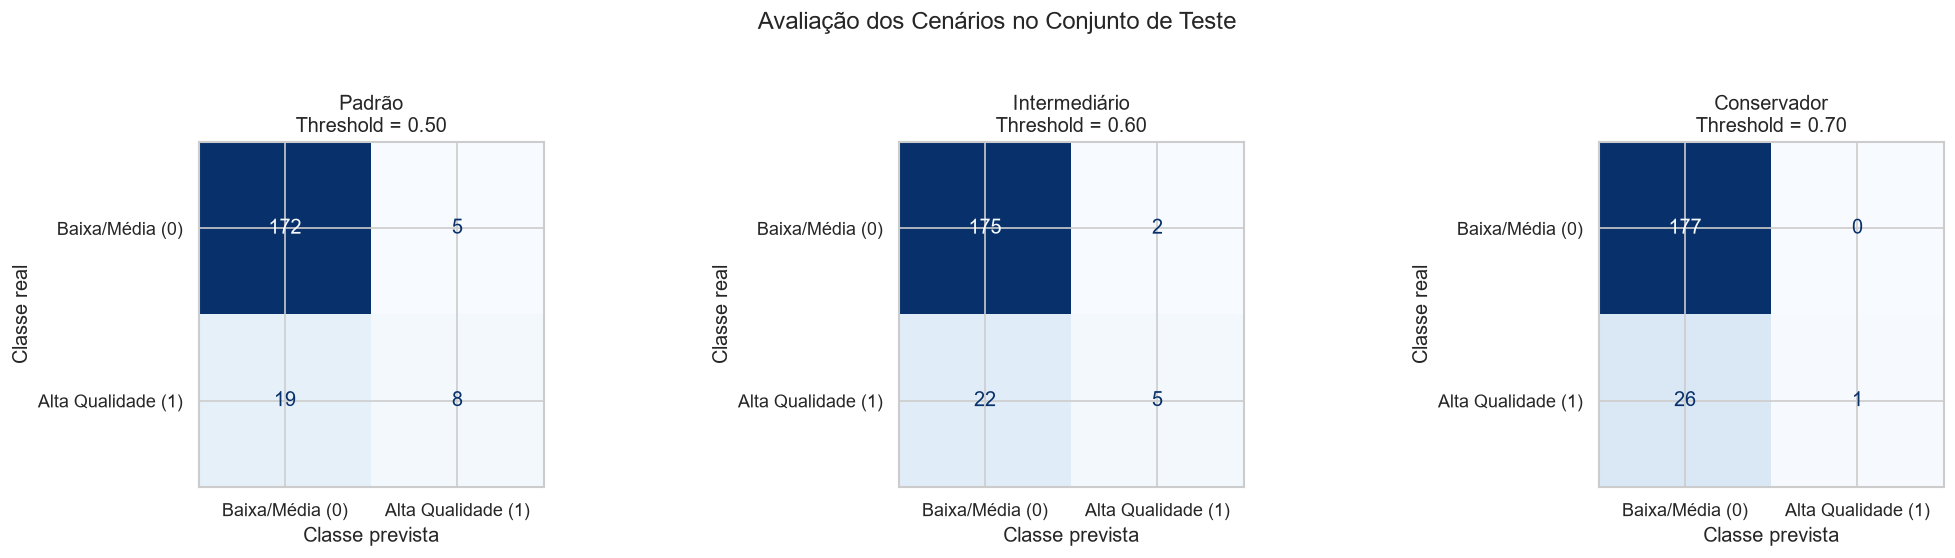

In [15]:
import matplotlib.pyplot as plt
from sklearn.metrics import (
    ConfusionMatrixDisplay,
    accuracy_score,
    average_precision_score,
    confusion_matrix,
    f1_score,
    precision_score,
    recall_score,
    roc_auc_score,
)
from sklearn.model_selection import GridSearchCV
from sklearn.base import clone

# Recupera o estimador e a grade da configuração selecionada pela Nested CV.
final_estimator, final_param_grid = search_configs[chosen_model_name]
X_train_final = datasets_fe[chosen_dataset_name]
X_test_final = X_test_fe if chosen_dataset_name == "13 Features (FE)" else X_test

# Reajusta hiperparâmetros em todo o conjunto de treino. O teste permanece isolado.
final_search = GridSearchCV(
    estimator=clone(final_estimator),
    param_grid=final_param_grid,
    cv=cv,
    scoring="average_precision",
    n_jobs=-1,
    refit=True,
    error_score="raise",
)
final_search.fit(X_train_final, y_train)
best_final_model = final_search.best_estimator_

y_test_proba = best_final_model.predict_proba(X_test_final)[:, 1]

print(f"Modelo candidato principal: {chosen_model_name}")
print(f"Conjunto de features: {chosen_dataset_name}")
print(f"Nested PR-AUC média: {chosen_row['Nested PR-AUC (média)']:.4f}")
print(f"Melhores hiperparâmetros no treino completo: {final_search.best_params_}")
print("Thresholds reportados: 0,50 (padrão), 0,60 (intermediário) e 0,70 (conservador).")

# Todos os cenários foram definidos antes de consultar as métricas do teste.
test_rows = []
for threshold, scenario_name in threshold_scenarios.items():
    y_pred_threshold = (y_test_proba >= threshold).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_test, y_pred_threshold, labels=[0, 1]).ravel()
    test_rows.append({
        "Modelo": chosen_model_name,
        "Features": chosen_dataset_name,
        "Cenário": scenario_name,
        "Threshold": threshold,
        "Qtd. previstas como alta": int(y_pred_threshold.sum()),
        "Accuracy": accuracy_score(y_test, y_pred_threshold),
        "Precision": precision_score(y_test, y_pred_threshold, zero_division=0),
        "Recall": recall_score(y_test, y_pred_threshold, zero_division=0),
        "F1-Score": f1_score(y_test, y_pred_threshold, zero_division=0),
        "ROC-AUC": roc_auc_score(y_test, y_test_proba),
        "PR-AUC": average_precision_score(y_test, y_test_proba),
        "VP": tp,
        "FP": fp,
        "FN": fn,
        "VN": tn,
    })

df_test_results = pd.DataFrame(test_rows).sort_values("Threshold").reset_index(drop=True)
display(df_test_results.round(4))

# Matrizes de confusão: uma para cada cenário pré-definido.
threshold_items = list(threshold_scenarios.items())
fig, axes = plt.subplots(1, len(threshold_items), figsize=(6 * len(threshold_items), 4.5))
axes = np.atleast_1d(axes)
labels = ["Baixa/Média (0)", "Alta Qualidade (1)"]

for ax, (threshold, scenario_name) in zip(axes, threshold_items):
    y_pred_threshold = (y_test_proba >= threshold).astype(int)
    cm = confusion_matrix(y_test, y_pred_threshold, labels=[0, 1])
    disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=labels)
    disp.plot(ax=ax, cmap="Blues", colorbar=False, values_format="d")
    ax.set_title(f"{scenario_name}\nThreshold = {threshold:.2f}")
    ax.set_xlabel("Classe prevista")
    ax.set_ylabel("Classe real")

plt.suptitle("Avaliação dos Cenários no Conjunto de Teste", y=1.03)
plt.tight_layout()
plt.show()

### 5.4 Síntese e Decisões da Avaliação e Comparação dos Modelos

A avaliação foi organizada em três momentos:

1. **Comparação de modelos por Nested Cross-Validation:** a validação interna seleciona hiperparâmetros e a externa estima o desempenho em observações não utilizadas nessa seleção. A métrica principal é a média da PR-AUC nos cinco folds externos, acompanhada do desvio-padrão.
2. **Comparação de thresholds com previsões OOF:** foram definidos previamente três cenários (0,50 padrão; 0,60 intermediário; 0,70 conservador). A tabela `df_threshold_scenarios_oof` compara Precision, Recall, F1-Score e contagens de erros para as cinco famílias de modelos finalistas.
3. **Avaliação final no teste:** a configuração principal foi escolhida pelo maior valor médio de PR-AUC na Nested CV, sem consultar o teste. Depois, o modelo foi reajustado no treino completo e os três cenários pré-definidos foram reportados no teste. O teste não foi usado para escolher o *threshold*.

**Escolha do modelo:** a configuração com maior média de PR-AUC na Nested CV é a candidata principal. Essa escolha é um critério comparativo transparente, mas não prova superioridade estatística definitiva, especialmente porque há apenas cinco folds e os desvios-padrão mostram variação entre eles. Os demais modelos permanecem como referências relevantes.

**Escolha do threshold:** não declaramos um vencedor automático entre 0,50, 0,60 e 0,70. O aumento do *threshold* normalmente torna as previsões positivas mais seletivas, mas reduz a quantidade de amostras identificadas. A decisão operacional depende do custo relativo de Falsos Positivos e Falsos Negativos, da capacidade de inspeção e da finalidade do modelo. Como esses dados ainda não foram quantificados, apresentamos os três cenários sem afirmar que um deles é universalmente melhor.

**Interpretação do teste:** ROC-AUC e PR-AUC avaliam a ordenação das probabilidades e, por isso, não mudam com o *threshold*. Precision, Recall, F1-Score e matriz de confusão mudam. Como o conjunto de teste contém poucas observações positivas, pequenas alterações na quantidade de acertos e erros podem alterar bastante as métricas.

## 6. Interpretação do Modelo — *Permutation Feature Importance*

### 6.1 Objetivo e método

Depois de selecionar o **Random Forest com 13 features** pela maior média de PR-AUC na Nested Cross-Validation, investigaremos quais variáveis mais contribuem para o desempenho preditivo desse modelo.

Utilizaremos **Permutation Feature Importance** (*importância por permutação*) sobre o conjunto de teste, mantendo o modelo já ajustado na etapa 5.3. Para cada variável, seus valores serão embaralhados 50 vezes, uma variável por vez, e mediremos quanto a métrica de avaliação diminui em relação ao desempenho original.

A métrica escolhida será **Average Precision (AP)**, implementada pelo `scoring="average_precision"` do Scikit-learn. No restante do projeto, essa métrica foi chamada de PR-AUC por convenção; tecnicamente, o `average_precision_score` calcula a média ponderada da precisão ao longo da curva Precision-Recall, sem interpolação trapezoidal.

**Como interpretar a importância:**
- Valor positivo maior: embaralhar a variável reduz mais a AP; o modelo depende mais daquela informação para manter seu desempenho.
- Valor próximo de zero: embaralhar a variável quase não altera a AP neste conjunto de avaliação.
- Valor negativo: a AP ficou ligeiramente maior após o embaralhamento; isso pode ocorrer por variação amostral e não prova que a variável seja prejudicial.

**Cuidado metodológico:** o teste será utilizado aqui para interpretar o modelo já congelado, não para selecionar hiperparâmetros, remover variáveis ou escolher o threshold. Essa análise é pós-modelagem. Como o conjunto de teste é pequeno, os resultados devem ser tratados como evidência exploratória, não como uma hierarquia definitiva das variáveis.


In [16]:
from sklearn.inspection import permutation_importance
from sklearn.metrics import average_precision_score

# O modelo best_final_model foi ajustado exclusivamente com os dados de treino
# na célula 5.3. Aqui usamos o conjunto de teste apenas para interpretação.
N_REPEATS_PFI = 50

permutation_result = permutation_importance(
    estimator=best_final_model,
    X=X_test_final,
    y=y_test,
    scoring="average_precision",
    n_repeats=N_REPEATS_PFI,
    random_state=RANDOM_STATE,
    n_jobs=-1,
)

# Desempenho de referência antes de embaralhar qualquer variável.
y_test_proba_pfi = best_final_model.predict_proba(X_test_final)[:, 1]
baseline_ap = average_precision_score(y_test, y_test_proba_pfi)

# A importância é a queda média na métrica após embaralhar cada variável.
df_permutation_importance = pd.DataFrame({
    "Variável": X_test_final.columns,
    "Importância média (queda na AP)": permutation_result.importances_mean,
    "Desvio-padrão das permutações": permutation_result.importances_std,
}).sort_values(
    "Importância média (queda na AP)", ascending=False
).reset_index(drop=True)

print(f"Average Precision de referência no teste: {baseline_ap:.4f}")
print(f"Número de observações no teste: {len(y_test)}")
print(f"Observações da classe positiva no teste: {int(y_test.sum())}")
print(f"Permutações por variável: {N_REPEATS_PFI}")

display(df_permutation_importance.round(4))


Average Precision de referência no teste: 0.5504
Número de observações no teste: 204
Observações da classe positiva no teste: 27
Permutações por variável: 50


,Variável,Importância média (queda na AP),Desvio-padrão das permutações
0,alcohol,0.1513,0.0430
1,sulphates,0.1161,0.0223
2,free_sulfur_ratio,0.0587,0.0352
3,residual sugar,0.0387,0.0111
4,citric acid,0.0251,0.0283
5,total sulfur dioxide,0.0140,0.0191
6,volatile acidity,0.0139,0.0420
7,fixed acidity,0.0112,0.0171
8,density,0.0082,0.0277
9,free sulfur dioxide,0.0056,0.0140


### 6.2 Visualização da importância das variáveis

O gráfico ordena as variáveis pela queda média na AP. As barras de erro representam **um desvio-padrão entre as 50 permutações**; não são intervalos de confiança e não incorporam toda a incerteza associada ao tamanho e à composição do conjunto de teste.


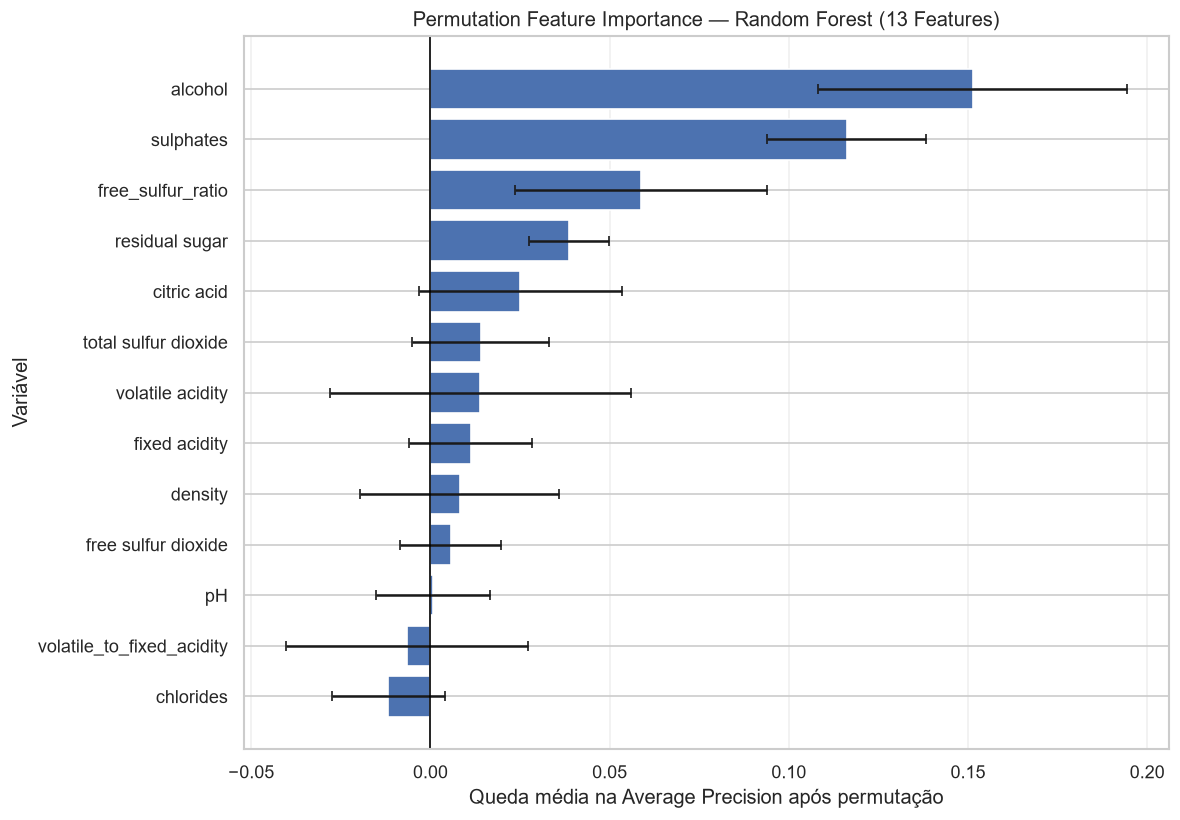

In [17]:
# Gráfico horizontal para facilitar a leitura dos nomes das variáveis.
plot_data = df_permutation_importance.sort_values(
    "Importância média (queda na AP)", ascending=True
)

fig, ax = plt.subplots(figsize=(10, 7))
ax.barh(
    plot_data["Variável"],
    plot_data["Importância média (queda na AP)"],
    xerr=plot_data["Desvio-padrão das permutações"],
    capsize=3,
)
ax.axvline(0, color="black", linewidth=1)
ax.set_title("Permutation Feature Importance — Random Forest (13 Features)")
ax.set_xlabel("Queda média na Average Precision após permutação")
ax.set_ylabel("Variável")
ax.grid(axis="x", alpha=0.3)
plt.tight_layout()
plt.show()


### 6.3 Leitura dos resultados e limitações

Na reprodução desta análise com o arquivo `WineQT.csv`, o modelo apresentou AP de referência de **0.5504** no conjunto de teste. As maiores quedas médias observadas após a permutação foram:

| Variável | Queda média na AP |
|---|---:|
| `alcohol` | 0.1513 |
| `sulphates` | 0.1161 |
| `free_sulfur_ratio` | 0.0587 |
| `residual sugar` | 0.0387 |
| `citric acid` | 0.0251 |

**Interpretação inicial:** `alcohol` e `sulphates` foram as variáveis com maior contribuição preditiva observada. A variável derivada `free_sulfur_ratio` também apresentou contribuição positiva relevante, seguida por `residual sugar` e `citric acid`. As demais variáveis tiveram efeitos menores nesta avaliação.

`volatile_to_fixed_acidity` e `chlorides` apresentaram importâncias médias ligeiramente negativas nesta execução. Isso **não significa** que sejam quimicamente prejudiciais ou que devam ser removidas automaticamente. Significa apenas que, neste modelo e neste conjunto de teste, embaralhá-las não reduziu a AP média.

**Limitações que precisam acompanhar a interpretação:**

1. **Amostra de teste pequena:** são 204 observações, das quais apenas 27 pertencem à classe Alta Qualidade. A importância pode variar em outra amostra.
2. **Variáveis correlacionadas:** quando duas ou mais variáveis carregam informações semelhantes, o modelo pode compensar a desorganização de uma utilizando as demais. Assim, a permutação individual pode subestimar a importância de variáveis correlacionadas. Isso merece atenção especial para as variáveis de SO₂ e de acidez.
3. **Importância não é causalidade:** a análise mede a dependência preditiva do modelo em relação às variáveis, e não demonstra que alterar uma característica causará aumento ou redução da qualidade do vinho.
4. **Não usar o ranking para eliminar features sem novo experimento:** qualquer remoção exige uma comparação controlada, refeita apenas no treino e validada por Nested CV.

Portanto, os resultados oferecem uma explicação global inicial do Random Forest, mas não devem ser apresentados como uma lei físico-química universal nem como uma prova de causalidade.


### 6.4 Importância por Grupos de Variáveis (*Grouped Permutation Feature Importance*)

A importância por permutação individual pode subestimar a contribuição de variáveis correlacionadas: quando uma variável é embaralhada isoladamente, outra variável semelhante pode continuar oferecendo informação ao modelo.

Para investigar esse efeito, faremos uma análise complementar por grupos. Em cada repetição, aplicaremos **a mesma permutação de linhas a todas as colunas de um grupo**. Assim, preservamos as relações internas entre as variáveis do grupo — inclusive a coerência entre as features originais e as derivadas — enquanto rompemos a associação do grupo com o alvo e com as variáveis que ficaram fora dele.

Os grupos foram definidos com base nas relações físico-químicas e nas features criadas no projeto:

| Grupo | Variáveis incluídas | Justificativa |
|---|---|---|
| Dióxido de enxofre | `free sulfur dioxide`, `total sulfur dioxide`, `free_sulfur_ratio` | Mantém a relação entre as duas medidas e a proporção derivada. |
| Acidez | `fixed acidity`, `volatile acidity`, `citric acid`, `pH`, `volatile_to_fixed_acidity` | Reúne medidas relacionadas à acidez e a razão derivada. |
| Álcool e densidade | `alcohol`, `density` | Preserva a relação observada entre teor alcoólico e densidade. |
| Variáveis isoladas | `residual sugar`, `sulphates`, `chlorides` | Permanecem separadas por não integrarem os blocos de dependência definidos acima. |

**Importante:** os grupos são hipóteses analíticas, não categorias químicas universais. A análise mede a contribuição preditiva conjunta de cada bloco para este modelo e este conjunto de teste. Não demonstra causalidade nem a importância intrínseca das características para a qualidade do vinho.

### 6.5 Implementação da permutação conjunta

A implementação abaixo reaproveita o `best_final_model` já ajustado na etapa 5.3 e o mesmo conjunto de teste usado na análise individual. **Nenhum modelo será treinado novamente.**

A validação verifica se todas as 13 features aparecem exatamente uma vez nos grupos. Para cada repetição, a mesma sequência de índices é aplicada às colunas do grupo. Isso é essencial: embaralhar cada coluna separadamente destruiria as relações internas que desejamos preservar.

In [18]:
from sklearn.metrics import average_precision_score

# Os grupos cobrem as 13 features do Random Forest selecionado.
# A mesma permutação de linhas será aplicada simultaneamente às colunas de cada grupo.
feature_groups = {
    "Dióxido de enxofre": [
        "free sulfur dioxide",
        "total sulfur dioxide",
        "free_sulfur_ratio",
    ],
    "Acidez": [
        "fixed acidity",
        "volatile acidity",
        "citric acid",
        "pH",
        "volatile_to_fixed_acidity",
    ],
    "Álcool e densidade": [
        "alcohol",
        "density",
    ],
    "Açúcar residual (isolada)": ["residual sugar"],
    "Sulfatos (isolada)": ["sulphates"],
    "Cloretos (isolada)": ["chlorides"],
}

# 1. Valida se não há colunas ausentes, desconhecidas ou repetidas nos grupos.
all_grouped_columns = [
    column
    for columns in feature_groups.values()
    for column in columns
]

repeated_columns = sorted({
    column for column in all_grouped_columns
    if all_grouped_columns.count(column) > 1
})
missing_columns = sorted(set(X_test_final.columns) - set(all_grouped_columns))
unknown_columns = sorted(set(all_grouped_columns) - set(X_test_final.columns))

if repeated_columns or missing_columns or unknown_columns:
    raise ValueError(
        "A definição dos grupos não corresponde às features do modelo. "
        f"Repetidas: {repeated_columns}; ausentes: {missing_columns}; "
        f"desconhecidas: {unknown_columns}."
    )

# 2. Recalcula o desempenho de referência e verifica consistência com a PFI individual.
y_test_proba_grouped = best_final_model.predict_proba(X_test_final)[:, 1]
grouped_baseline_ap = average_precision_score(y_test, y_test_proba_grouped)

if "baseline_ap" in globals() and not np.isclose(
    grouped_baseline_ap, baseline_ap, atol=1e-12
):
    raise RuntimeError(
        "A AP de referência desta etapa difere da AP calculada na PFI individual."
    )

# 3. Calcula a queda de AP após permutar cada grupo conjuntamente.
N_REPEATS_GROUPED_PFI = 50
rng_grouped = np.random.default_rng(RANDOM_STATE + 100)
grouped_rows = []

for group_name, group_columns in feature_groups.items():
    ap_drops = []
    permuted_ap_scores = []

    for repeat in range(N_REPEATS_GROUPED_PFI):
        row_permutation = rng_grouped.permutation(len(X_test_final))
        X_permuted = X_test_final.copy()

        # Uma única permutação comum preserva a estrutura interna do grupo.
        X_permuted.loc[:, group_columns] = (
            X_test_final.iloc[row_permutation][group_columns].to_numpy()
        )

        permuted_probabilities = best_final_model.predict_proba(
            X_permuted
        )[:, 1]
        permuted_ap = average_precision_score(y_test, permuted_probabilities)

        permuted_ap_scores.append(permuted_ap)
        ap_drops.append(grouped_baseline_ap - permuted_ap)

    grouped_rows.append({
        "Grupo": group_name,
        "Nº de variáveis": len(group_columns),
        "Variáveis": ", ".join(group_columns),
        "Importância média (queda na AP)": float(np.mean(ap_drops)),
        "Desvio-padrão das permutações": float(np.std(ap_drops, ddof=0)),
        "AP média após permutação": float(np.mean(permuted_ap_scores)),
    })

df_grouped_permutation_importance = (
    pd.DataFrame(grouped_rows)
    .sort_values("Importância média (queda na AP)", ascending=False)
    .reset_index(drop=True)
)

print(f"Average Precision de referência: {grouped_baseline_ap:.4f}")
print(f"Observações no teste: {len(y_test)}")
print(f"Observações positivas no teste: {int(y_test.sum())}")
print(f"Permutações por grupo: {N_REPEATS_GROUPED_PFI}")
print("A mesma permutação de linhas foi aplicada a todas as colunas de cada grupo.")
display(df_grouped_permutation_importance.round(4))

Average Precision de referência: 0.5504
Observações no teste: 204
Observações positivas no teste: 27
Permutações por grupo: 50
A mesma permutação de linhas foi aplicada a todas as colunas de cada grupo.


,Grupo,Nº de variáveis,Variáveis,Importância média (queda na AP),Desvio-padrão das permutações,AP média após permutação
0,Álcool e densidade,2,"alcohol, density",0.1941,0.0528,0.3563
1,Acidez,5,"fixed acidity, volatile acidity, citric acid, ...",0.1636,0.0567,0.3868
2,Sulfatos (isolada),1,sulphates,0.1150,0.0272,0.4354
3,Dióxido de enxofre,3,"free sulfur dioxide, total sulfur dioxide, fre...",0.0756,0.0379,0.4748
4,Açúcar residual (isolada),1,residual sugar,0.0418,0.0091,0.5086
5,Cloretos (isolada),1,chlorides,-0.0151,0.0181,0.5654


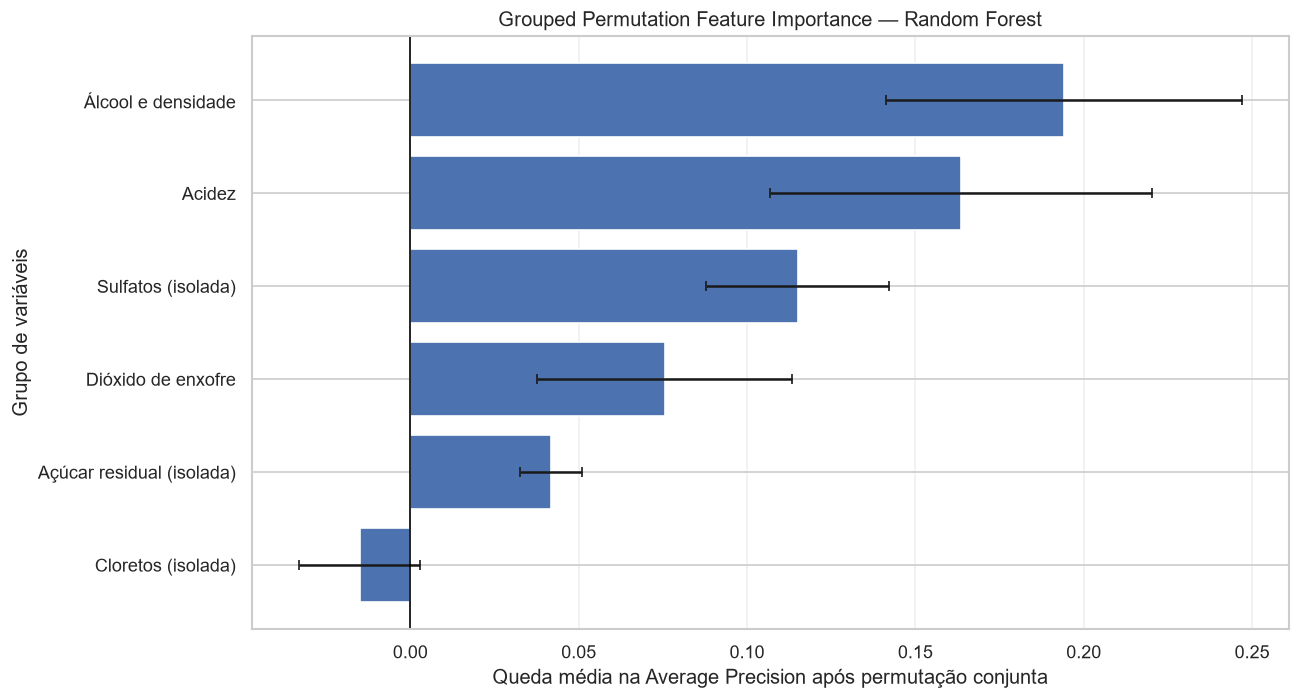

In [19]:
# Gráfico horizontal: a queda média na AP representa a importância conjunta do grupo.
plot_grouped = df_grouped_permutation_importance.sort_values(
    "Importância média (queda na AP)", ascending=True
)

fig, ax = plt.subplots(figsize=(11, 6))
ax.barh(
    plot_grouped["Grupo"],
    plot_grouped["Importância média (queda na AP)"],
    xerr=plot_grouped["Desvio-padrão das permutações"],
    capsize=3,
)
ax.axvline(0, color="black", linewidth=1)
ax.set_title("Grouped Permutation Feature Importance — Random Forest")
ax.set_xlabel("Queda média na Average Precision após permutação conjunta")
ax.set_ylabel("Grupo de variáveis")
ax.grid(axis="x", alpha=0.3)
plt.tight_layout()
plt.show()

### 6.6 Interpretação dos resultados por grupos e limitações

Na execução de referência com `WineQT.csv`, a AP de referência foi **0,5504**. Os grupos com maiores quedas médias foram **Álcool e densidade** e **Acidez**, seguidos por **Sulfatos** e **Dióxido de enxofre**. Os valores exatos são exibidos na tabela `df_grouped_permutation_importance` e no gráfico acima.

**Como interpretar:** se a permutação conjunta de um grupo provoca uma queda maior na AP do que a permutação individual de suas variáveis, isso sugere que o bloco contém informação preditiva compartilhada ou complementar que não era totalmente capturada pelas permutações individuais. Por exemplo, o modelo pode aproveitar sinais distribuídos entre diferentes medidas de acidez; ao embaralhar uma delas isoladamente, as demais continuam disponíveis.

**Limitações importantes:**

1. **Importância conjunta não é soma das importâncias individuais.** Os resultados não devem ser somados nem comparados como se fossem parcelas independentes. Variáveis correlacionadas e interações podem gerar redundância ou complementaridade.
2. **A escolha dos grupos influencia o resultado.** Grupos foram definidos por hipóteses do domínio e pelas features derivadas do projeto. Outros agrupamentos poderiam produzir resultados diferentes.
3. **A permutação quebra relações entre grupos.** Preservamos as relações internas de cada grupo, mas combinamos esse bloco com valores das variáveis externas pertencentes a outras observações. Isso é intencional para medir a dependência do modelo, mas pode criar combinações menos comuns na distribuição original.
4. **Desvio-padrão não é intervalo de confiança.** A variação entre as 50 permutações mede principalmente a variabilidade do procedimento de embaralhamento; não representa toda a incerteza amostral do teste, que contém apenas 204 observações e 27 positivas.
5. **Análise exploratória, não seleção de atributos.** O resultado não será usado para remover variáveis ou retreinar o modelo. Qualquer mudança exigiria um novo experimento definido no treino e avaliado por Nested Cross-Validation.

As variáveis isoladas (`residual sugar`, `sulphates` e `chlorides`) foram mantidas como referências de comparação. Para elas, a permutação conjunta equivale à permutação individual de uma única coluna, embora os valores possam variar um pouco devido à semente aleatória utilizada.

## 7. Conclusões Gerais, Limitações e Próximos Passos

### 7.1 Síntese dos resultados técnicos

O objetivo foi classificar amostras de vinho em duas categorias, conforme a regra definida no desafio: **alta qualidade** quando `quality >= 7` e **baixa/média qualidade** quando `quality < 7`.

A base original continha **1.143 registros**. A auditoria identificou 125 registros excedentes em perfis físico-químicos repetidos; adotando a premissa de manter uma ocorrência por perfil e rótulo, a base de modelagem passou a conter **1.018 registros**. A deduplicação é uma decisão metodológica, pois os dados não permitem comprovar se os perfis repetidos representam duplicações de cadastro ou amostras independentes com medições coincidentes.

Após a divisão estratificada, foram utilizados **814 registros para treino** e **204 para teste**. A classe positiva permaneceu minoritária: 13,51% no treino e 13,24% no teste. O teste contém somente **27 observações positivas**, o que torna Precision e Recall sensíveis a poucos acertos ou erros.

A comparação por *Nested Cross-Validation* apontou o **Random Forest com 13 variáveis (11 originais + 2 derivadas)** como a configuração candidata principal, com PR-AUC média de **0,5804** (desvio-padrão de 0,0426) e ROC-AUC média de **0,8854** nos folds externos. O Random Forest com as 11 variáveis originais obteve PR-AUC média de 0,5710. A diferença de 0,0094 é descritiva: não foi realizado um teste estatístico que permita afirmar superioridade significativa da versão com *Feature Engineering*.

No ajuste final feito apenas com o conjunto de treino, os hiperparâmetros selecionados foram `n_estimators=300`, `max_depth=6` e `min_samples_leaf=1`. No conjunto de teste, a Average Precision foi **0,5504** e a ROC-AUC foi **0,8818**. Esses valores descrevem o modelo ajustado no treino e avaliado uma única vez no holdout.

### 7.2 Comparação dos cenários de threshold

Os três *thresholds* foram mantidos como cenários de sensibilidade. Nenhum foi declarado universalmente ótimo, porque ainda não temos custos de negócio para Falsos Positivos e Falsos Negativos.

| Cenário | Threshold | Precision | Recall | F1-Score | VP | FP | FN | VN |
|---|---:|---:|---:|---:|---:|---:|---:|---:|
| Padrão | 0,50 | 61,54% | 29,63% | 40,00% | 8 | 5 | 19 | 172 |
| Intermediário | 0,60 | 71,43% | 18,52% | 29,41% | 5 | 2 | 22 | 175 |
| Conservador | 0,70 | 100,00% | 3,70% | 7,14% | 1 | 0 | 26 | 177 |

No teste, o cenário 0,50 identificou mais amostras realmente positivas (maior Recall entre os três), mas gerou cinco Falsos Positivos. O cenário 0,60 reduziu os Falsos Positivos para dois, ao custo de deixar mais amostras positivas sem identificação. O cenário 0,70 classificou apenas uma amostra como alta qualidade; embora essa previsão tenha sido correta, a Precision de 100% se baseia em **uma única previsão positiva** e veio acompanhada de Recall de apenas 3,70%. Portanto, esse resultado não deve ser interpretado como evidência de desempenho operacional perfeito.

A escolha depende da finalidade: para uma triagem inicial que queira deixar passar menos candidatos, 0,50 é um cenário a investigar; para uma seleção mais restritiva, 0,60 pode ser considerado. Antes de recomendar um limite para uso real, a empresa precisaria informar custos, capacidade de análise sensorial e consequências de cada tipo de erro. O modelo deve apoiar a priorização de amostras para avaliação especializada, não substituir a avaliação sensorial.

A ROC-AUC (0,8818) e a Average Precision (0,5504) não mudam entre os três *thresholds*, pois avaliam o desempenho de ordenação dos *scores* e não dependem da conversão desses *scores* em classes por um limite específico.

### 7.3 Interpretação das variáveis

Na Permutation Feature Importance individual, as maiores quedas médias na Average Precision ocorreram ao embaralhar `alcohol` (0,1513), `sulphates` (0,1161) e `free_sulfur_ratio` (0,0587). Na análise por grupos, destacaram-se **Álcool e densidade** (0,1941) e **Acidez** (0,1636), seguidos por **Sulfatos** (0,1150) e **Dióxido de enxofre** (0,0756).

Esses resultados indicam quais informações foram mais úteis para as previsões deste Random Forest nesta amostra e com esta métrica. Não demonstram causalidade e não significam que alterar diretamente uma característica físico-química aumentará a qualidade do vinho. A comparação entre grupos também deve considerar que eles possuem quantidades diferentes de variáveis e que a permutação pode gerar combinações menos comuns na distribuição original.

### 7.4 Implicações para o negócio

O modelo pode ser considerado um **instrumento experimental de apoio à triagem**: a partir de medições físico-químicas, ele atribui um *score* e indica quais amostras merecem atenção prioritária. Uma vinícola poderia testar esse fluxo em conjunto com a equipe de enologia, registrando as previsões e comparando-as posteriormente com a avaliação sensorial real.

Para uma aplicação responsável, o resultado do modelo não deve ser apresentado como certificação de qualidade nem como recomendação automática de alteração do processo produtivo. O *score* de `predict_proba` será tratado como **score do modelo**, não como probabilidade calibrada, pois a calibração das probabilidades não foi avaliada neste estudo.

### 7.5 Limitações do estudo

- **Tamanho amostral e desbalanceamento:** a classe positiva é minoritária e o teste contém apenas 27 amostras positivas; pequenas diferenças de classificação alteram sensivelmente as métricas.
- **Deduplicação:** os perfis repetidos tinham os mesmos atributos físico-químicos e rótulos, mas a base não permite determinar se são registros duplicados ou amostras diferentes com medições coincidentes.
- **Escopo das variáveis:** os dados disponíveis não abrangem todos os fatores que podem influenciar a qualidade percebida, como safra, origem, armazenamento, práticas produtivas e avaliações sensoriais detalhadas.
- **Threshold operacional:** não foram fornecidos custos de erros nem capacidade de inspeção, portanto não há base para declarar um limite comercial ideal.
- **Validação externa:** Nested CV e holdout fornecem evidências internas mais cuidadosas, mas não substituem testes em novos lotes, safras, produtores ou equipamentos de medição.
- **Importância preditiva:** PFI é uma análise de dependência do modelo e pode ser afetada por variáveis correlacionadas, agrupamentos escolhidos e tamanho da amostra. Não é evidência causal.
- **Calibração:** não avaliamos se os scores previstos correspondem a frequências observadas de acerto; por isso, não os chamamos de probabilidades calibradas.

### 7.6 Próximos passos

1. **Disponibilizar o modelo:** salvar com `pickle` o estimador final avaliado, acompanhado das colunas esperadas, das regras de *Feature Engineering*, dos hiperparâmetros e das versões das bibliotecas.
2. **Criar um fluxo de predição:** receber um CSV com as 11 variáveis físico-químicas, validar as entradas, criar as duas features derivadas e gerar um CSV com o *score* e a classe prevista.
3. **Validar com dados futuros:** comparar as previsões com avaliações sensoriais reais de novos lotes antes de qualquer uso operacional.
4. **Definir o threshold com o negócio:** considerar custo de Falsos Positivos, custo de Falsos Negativos e capacidade de revisão humana.
5. **Monitorar e atualizar:** acompanhar mudanças nos dados de entrada e no desempenho; retreinar somente com dados rotulados e nova avaliação apropriada.



## 8. Exportação do modelo com Pickle

Nesta etapa, vamos salvar o estimador que foi efetivamente avaliado na seção 5.3. Ele foi ajustado somente com os 80% destinados ao treino; o conjunto de teste permanece fora do ajuste e continua representando a avaliação independente documentada acima.

Além do objeto do modelo, salvaremos metadados para que o script de predição saiba quais colunas deve receber e qual versão de bibliotecas foi utilizada. As regras de criação das duas features derivadas ficam centralizadas em `src/features.py`, que será reutilizado tanto pelo notebook quanto pelo script de predição.

> **Segurança:** arquivos Pickle devem ser carregados somente quando foram criados por você ou por uma fonte confiável. Carregar um arquivo Pickle não confiável pode executar código malicioso.


In [20]:
import pickle
import platform
import sklearn

# O diretório é criado automaticamente caso ainda não exista.
MODEL_DIR = PROJECT_ROOT / "models"
MODEL_DIR.mkdir(parents=True, exist_ok=True)
MODEL_PATH = MODEL_DIR / "wine_quality_model.pkl"

# O pacote guarda o estimador e informações necessárias para utilizá-lo depois.
model_bundle = {
    "artifact_version": "1.0",
    "model": best_final_model,
    "model_name": chosen_model_name,
    "dataset_name": chosen_dataset_name,
    "raw_feature_columns": list(X_train.columns),
    "model_feature_columns": list(X_train_final.columns),
    "target_definition": "1 = quality >= 7; 0 = quality < 7",
    "feature_engineering": {
        "free_sulfur_ratio": "free sulfur dioxide / total sulfur dioxide",
        "volatile_to_fixed_acidity": "volatile acidity / fixed acidity",
    },
    "best_params": final_search.best_params_,
    "threshold_scenarios": [0.50, 0.60, 0.70],
    "training_rows": int(len(X_train_final)),
    "test_rows": int(len(X_test_final)),
    "training_note": (
        "Estimador ajustado apenas na partição de treino (80% da base deduplicada). "
        "O conjunto de teste não participou do ajuste."
    ),
    "sklearn_version": sklearn.__version__,
    "python_version": platform.python_version(),
}

with MODEL_PATH.open("wb") as model_file:
    pickle.dump(model_bundle, model_file, protocol=pickle.HIGHEST_PROTOCOL)

print(f"Modelo salvo com sucesso em: {MODEL_PATH.relative_to(PROJECT_ROOT).as_posix()}")
print(f"Algoritmo: {model_bundle['model_name']}")
print(f"Features de entrada: {len(model_bundle['raw_feature_columns'])}")
print(f"Features utilizadas pelo modelo: {len(model_bundle['model_feature_columns'])}")
print(f"Versão do Scikit-learn: {model_bundle['sklearn_version']}")
print("O modelo salvo é o mesmo estimador avaliado no conjunto de teste.")


Modelo salvo com sucesso em: models/wine_quality_model.pkl
Algoritmo: Random Forest
Features de entrada: 11
Features utilizadas pelo modelo: 13
Versão do Scikit-learn: 1.9.1
O modelo salvo é o mesmo estimador avaliado no conjunto de teste.



## 9. Demonstração do fluxo de predição com dados em formato CSV

Depois de exportar o modelo com `pickle`, vamos validar se o artefato salvo produz os mesmos scores do estimador mantido em memória. Em seguida, criaremos um pequeno arquivo de demonstração e compararemos as classificações nos três thresholds estudados (0,50; 0,60; 0,70).

> **Importante:** as linhas usadas nesta demonstração são selecionadas a partir das variáveis do conjunto de teste apenas para exercitar o fluxo de software. A coluna-alvo não é usada para selecioná-las nem é incluída no CSV. Esta demonstração não constitui uma nova validação independente do modelo e não deve ser usada para escolher o threshold.


### 9.1 Conferência do modelo salvo

Carregamos o pacote salvo e verificamos se o modelo serializado retorna os mesmos scores que o estimador utilizado na avaliação. Essa checagem ajuda a detectar divergências entre o modelo avaliado e o artefato usado no script de predição.


In [21]:
from src.predict import load_model_bundle, predict_dataframe

# Carrega o arquivo pickle criado na seção 8.
loaded_model_bundle = load_model_bundle(MODEL_PATH)

# Compara os scores do estimador em memória com os scores do artefato carregado.
scores_in_memory = best_final_model.predict_proba(X_test_final)[:, 1]
scores_from_pickle = loaded_model_bundle["model"].predict_proba(X_test_final)[:, 1]

if not np.allclose(scores_in_memory, scores_from_pickle, rtol=0, atol=1e-12):
    raise AssertionError("Os scores do modelo carregado diferem dos scores do estimador avaliado.")

print("Modelo pickle carregado com sucesso.")
print("Os scores do modelo salvo coincidem com os do estimador avaliado.")
print(f"Versão do Scikit-learn registrada: {loaded_model_bundle['sklearn_version']}")
print(f"Quantidade de variáveis de entrada: {len(loaded_model_bundle['raw_feature_columns'])}")

Modelo pickle carregado com sucesso.
Os scores do modelo salvo coincidem com os do estimador avaliado.
Versão do Scikit-learn registrada: 1.9.1
Quantidade de variáveis de entrada: 11


### 9.2 Criação de um CSV demonstrativo

Para demonstrar a mudança de classificação, precisamos de exemplos com scores em faixas diferentes. Selecionaremos uma observação abaixo de 0,50, uma entre 0,50 e 0,60, uma entre 0,60 e 0,70 e uma igual ou superior a 0,70. A seleção usa somente os scores calculados a partir de `X_test`; `y_test` não participa desta demonstração.

O arquivo de entrada conterá somente `sample_id` e as 11 variáveis físico-químicas originais, exatamente como o script `src.predict` espera receber de um usuário.

In [22]:
# Scores calculados pelo modelo já salvo; não usamos y_test nesta seleção.
score_by_index = pd.Series(scores_from_pickle, index=X_test.index)

demo_bands = {
    "abaixo_050": (score_by_index < 0.50, 0.45),
    "entre_050_060": ((score_by_index >= 0.50) & (score_by_index < 0.60), 0.55),
    "entre_060_070": ((score_by_index >= 0.60) & (score_by_index < 0.70), 0.65),
    "a_partir_070": (score_by_index >= 0.70, 0.75),
}

selected_indices = []
selection_rows = []

for band_name, (band_mask, reference_score) in demo_bands.items():
    candidates = score_by_index.loc[band_mask]
    if candidates.empty:
        raise ValueError(
            f"Não há observações no conjunto de teste para a faixa {band_name}. "
            "Ajuste a demonstração para as faixas disponíveis, sem alterar o modelo."
        )
    selected_index = (candidates - reference_score).abs().idxmin()
    selected_indices.append(selected_index)
    selection_rows.append({
        "Faixa selecionada": band_name,
        "Índice interno": int(selected_index),
        "Score do modelo": float(score_by_index.loc[selected_index]),
    })

df_demo_selection = pd.DataFrame(selection_rows)
display(df_demo_selection.round(4))

# Monta o arquivo sem quality ou target. Essas informações não existem em uma entrada futura.
demo_input = X_test.loc[selected_indices, RAW_FEATURES].copy().reset_index(drop=True)
demo_input.insert(0, "sample_id", [f"DEMO_{name.upper()}" for name in demo_bands])

EXAMPLE_DIR = PROJECT_ROOT / "data" / "examples"
EXAMPLE_DIR.mkdir(parents=True, exist_ok=True)
DEMO_INPUT_PATH = EXAMPLE_DIR / "threshold_demo_from_holdout.csv"
demo_input.to_csv(DEMO_INPUT_PATH, index=False, encoding="utf-8-sig")

print(f"Arquivo demonstrativo criado em: {DEMO_INPUT_PATH.relative_to(PROJECT_ROOT).as_posix()}")
print(f"Colunas incluídas: {len(demo_input.columns) - 1} variáveis físico-químicas + sample_id")
display(demo_input)

,Faixa selecionada,Índice interno,Score do modelo
0,abaixo_050,994,0.4419
1,entre_050_060,511,0.5309
2,entre_060_070,178,0.6279
3,a_partir_070,587,0.7806


Arquivo demonstrativo criado em: data/examples/threshold_demo_from_holdout.csv
Colunas incluídas: 11 variáveis físico-químicas + sample_id


,sample_id,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol
0,DEMO_ABAIXO_050,6.7,0.16,0.64,2.1,0.059,24.0,52.0,0.99494,3.34,0.71,11.2
1,DEMO_ENTRE_050_060,10.1,0.27,0.54,2.3,0.065,7.0,26.0,0.99531,3.17,0.53,12.5
2,DEMO_ENTRE_060_070,10.3,0.32,0.45,6.4,0.073,5.0,13.0,0.99760,3.23,0.82,12.6
3,DEMO_A_PARTIR_070,8.7,0.33,0.38,3.3,0.063,10.0,19.0,0.99468,3.30,0.73,12.0


### 9.3 Comparação das classificações nos três thresholds

A função `predict_dataframe` é a mesma utilizada pelo script de linha de comando. Vamos processar o mesmo CSV três vezes, alterando somente o threshold. Os scores devem permanecer iguais; apenas a classe prevista pode mudar.

In [23]:
demo_results = {}
df_demo_comparison = demo_input[["sample_id"]].copy()
reference_scores = None

PREDICTION_DIR = PROJECT_ROOT / "results" / "predictions"
PREDICTION_DIR.mkdir(parents=True, exist_ok=True)

for threshold, scenario_name in threshold_scenarios.items():
    predictions = predict_dataframe(demo_input, loaded_model_bundle, threshold)
    current_scores = predictions["score_modelo_alta_qualidade"].to_numpy()

    if reference_scores is None:
        reference_scores = current_scores
        df_demo_comparison["Score do modelo"] = current_scores
    elif not np.allclose(reference_scores, current_scores, rtol=0, atol=1e-12):
        raise AssertionError("Os scores mudaram ao alterar apenas o threshold.")

    threshold_label = f"{threshold:.2f}".replace(".", "_")
    df_demo_comparison[f"Classe — {scenario_name} ({threshold:.2f})"] = predictions["classificacao_prevista"]
    demo_results[threshold] = predictions
    output_path = PREDICTION_DIR / f"threshold_demo_{threshold_label}.csv"
    predictions.to_csv(output_path, index=False, encoding="utf-8-sig")

display(df_demo_comparison.round(4))

comparison_path = PREDICTION_DIR / "threshold_demo_comparison.csv"
df_demo_comparison.to_csv(comparison_path, index=False, encoding="utf-8-sig")
print(f"Comparação salva em: {comparison_path.relative_to(PROJECT_ROOT).as_posix()}")
print("Os scores permaneceram constantes nos três cenários; somente as classificações foram alteradas pelo threshold.")

,sample_id,Score do modelo,Classe — Padrão (0.50),Classe — Intermediário (0.60),Classe — Conservador (0.70)
0,DEMO_ABAIXO_050,0.4419,Baixa/Média qualidade,Baixa/Média qualidade,Baixa/Média qualidade
1,DEMO_ENTRE_050_060,0.5309,Alta qualidade,Baixa/Média qualidade,Baixa/Média qualidade
2,DEMO_ENTRE_060_070,0.6279,Alta qualidade,Alta qualidade,Baixa/Média qualidade
3,DEMO_A_PARTIR_070,0.7806,Alta qualidade,Alta qualidade,Alta qualidade


Comparação salva em: results/predictions/threshold_demo_comparison.csv
Os scores permaneceram constantes nos três cenários; somente as classificações foram alteradas pelo threshold.


### 9.4 Como repetir a demonstração pelo PowerShell

Depois de executar as células anteriores, o arquivo `data/examples/threshold_demo_from_holdout.csv` estará disponível. A partir da raiz do projeto, com o ambiente virtual ativado, execute:

```powershell
python -m src.predict --input data/examples/threshold_demo_from_holdout.csv --threshold 0.50 --output results/predictions/cli_demo_050.csv
python -m src.predict --input data/examples/threshold_demo_from_holdout.csv --threshold 0.60 --output results/predictions/cli_demo_060.csv
python -m src.predict --input data/examples/threshold_demo_from_holdout.csv --threshold 0.70 --output results/predictions/cli_demo_070.csv
```

**Leitura correta do teste:** este exercício demonstra que o artefato pode receber um CSV e aplicar diferentes limites. As amostras vieram do conjunto de teste já utilizado na avaliação; portanto, não representam validação em novos lotes, safras ou produtores. Para uso real, será necessário testar dados futuros rotulados e definir o threshold com a área de negócio.